<div align="center">

# Eliminación de artefactos en imágenes de endoscopía
### Avance 1. Exploración de datos
**Proyecto Integrador** · 4 de octubre del 2026

</div>

---

| Integrante | Matrícula |
|---|---|
| Mario Raúl García Ramírez | A01658682 |
| Javier Emmanuel García Escobedo | A01411206 |
| Juan Miguel Molina Reyes | A01796655 |

**Profesor:** Dr. Gilberto Ochoa Ruiz, EIC Computación  
**Patrocinador:** Dr. Gerardo Jesús Camacho González, INSiDE Lab

---

### Contenido
1. Estrategia de exploración de datos
   - 1.1 Descripción general del conjunto de datos
   - 1.2 Estrategia de muestreo
2. Obtención de los datos
   - 2.1 Origen y composición de la muestra · 2.2 Acceso a los vídeos desde Google Colab
3. Plan de exploración
   - 3.1 Pasos de exploración
   - 3.2 Implicaciones para la partición de los datos
4. Análisis exploratorio de las imágenes
   - 4.1 Naturaleza de las imágenes · 4.2 Funciones de carga · 4.3 Inventario e integridad · 4.4 Galería de fotogramas
   - 4.5 Estadísticas por fotograma · 4.6 Formación de la imagen · 4.7 Color · 4.8 Brillo, contraste y calidad · 4.9 Contenido frecuencial · 4.10 Relaciones entre métricas
   - 4.11 Efecto de los residuos · 4.12 Mapas de referencia · 4.13 Redundancia temporal · 4.14 Resumen · 4.15 Hallazgos
5. Referencias

## 1. Estrategia de exploración de datos

### 1.1 Descripción general del conjunto de datos

El conjunto de datos C3VDv2 [1] contiene vídeos de colonoscopia grabados en un fantoma de colon de silicona. Los vídeos se dividen en tres categorías que difieren en su propósito, tamaño y anotaciones disponibles (Tabla 1). Los vídeos registrados se graban en un fantoma estático e incluyen datos de referencia (*ground truth*) a nivel de píxel para cada fotograma (profundidad, normales de superficie, flujo óptico, entre otros). Los vídeos de deformación y de cribado proporcionan únicamente fotogramas RGB y poses de la cámara. En total, los 192 vídeos se obtuvieron a partir de 60 segmentos distintos del fantoma e incluyen artefactos realistas como residuos fecales, acumulaciones de moco, sangre y espuma, lo que hace al conjunto especialmente adecuado para el problema de eliminación de artefactos.

**Tabla 1.** Composición del conjunto de datos C3VDv2. GT: datos de referencia a nivel de píxel.

| Categoría   | Vídeos | Fotogramas | % de fotogramas | Anotaciones |
|-------------|-------:|-----------:|----------------:|-------------|
| Registrados | 169    | 67 886     | 40,1            | GT, poses |
| Deformación | 15     | 6 185      | 3,7             | Poses (solo si la cámara se mueve) |
| Cribado     | 8      | 95 300     | 56,3            | Poses |
| **Total**   | **192**| **169 371**| **100,0**       | |

Dos propiedades de esta composición determinan la estrategia descrita a continuación. En primer lugar, las categorías están muy desequilibradas en número de fotogramas: ocho vídeos de cribado (unos 11 900 fotogramas cada uno) representan más de la mitad del total, mientras que los quince vídeos de deformación representan menos del 4 %. En segundo lugar, los vídeos registrados están emparejados por diseño: para cada segmento del fantoma se grabaron hasta tres vídeos (**v1**: colon limpio, trayectoria de referencia; **v2**: colon limpio, trayectoria y parámetros de adquisición distintos; **v3**: colon con residuos, misma trayectoria y parámetros que v2). El par v2/v3 aísla el efecto de los residuos, por lo que estos vídeos se analizan como grupos emparejados.

Cada archivo del repositorio sigue una convención de nombres compuesta por cuatro partes: el fantoma de silicona (`c1` o `c2`), el segmento anatómico del colon (por ejemplo, `cecum`, `ascending`, `transverse`, `descending`, `sigmoid` o `rectum`), la combinación de textura y color (`t1` a `t4`), y el tipo de vídeo (`v1`, `v2` o `v3` para vídeos Registrados; `v4` para vídeos de Deformación). Por ejemplo, `c1_cecum_t1_v1.zip` corresponde al fantoma c1, segmento cecum, textura 1, versión 1. No todas las combinaciones de segmento, textura y versión están disponibles en todos los casos.

### 1.2 Estrategia de muestreo

Debido al tamaño del conjunto completo (aproximadamente 800 GB), disponible en el repositorio de la Universidad Johns Hopkins [2], la exploración se realiza sobre un subconjunto representativo. La unidad de muestreo es el *vídeo* y no el fotograma individual, ya que los fotogramas solo son interpretables junto con su secuencia, las poses de la cámara y los mapas de referencia. El muestreo se estratifica por categoría para que todas estén representadas:

- **Registrados:** una selección aleatoria de segmentos del fantoma, descargando *todas* las versiones disponibles (v1, v2, v3) de cada segmento seleccionado, para conservar el diseño emparejado.
- **Deformación:** una selección aleatoria de vídeos, equilibrada en lo posible entre movimiento de cámara estático y lineal.
- **Cribado:** una o más secuencias de retirada completas.

Este era el diseño de muestreo previsto. Como se explica a continuación y en la sección 2, el tamaño de los archivos y el bloqueo del repositorio a las descargas automatizadas obligaron a trabajar con una muestra más reducida.

#### Verificación de tamaños y restricción de almacenamiento

Al revisar los tamaños reales de los archivos en el repositorio, se encontró que estos son considerablemente más grandes de lo anticipado: los vídeos Registrados pesan entre 1.1 y 10.4 GB por archivo, los de Cribado entre 12.7 y 19.8 GB cada uno, y los de Deformación, más livianos, entre 0.47 y 1.3 GB. Esto implica que es necesario que todos los integrantes del equipo cuenten con almacenamiento local suficiente para descargar y procesar las muestras seleccionadas, o bien evaluar el uso de almacenamiento compartido (servidor de nube), antes de poder llevar a cabo la exploración y las etapas posteriores del proyecto de manera exitosa. Se optó por el almacenamiento compartido: los vídeos se guardaron en una carpeta del equipo en Google Drive y el análisis se ejecuta en Google Colab (sección 2).

---

## 2. Obtención de los datos

### 2.1 Origen y composición de la muestra

El plan inicial contemplaba descargar la muestra estratificada de 1.2 directamente del repositorio de la Universidad Johns Hopkins [2] mediante su API. En la práctica, el repositorio rechazó las descargas automatizadas (error HTTP 403), de modo que cada vídeo tenía que descargarse a mano desde el navegador, y a esto se sumó el tamaño de los archivos (de 1.1 a 19.8 GB por vídeo). Por ello, los vídeos se descargaron manualmente desde la página del repositorio y se almacenaron en una carpeta compartida del equipo en Google Drive (`Equipo19/raw`). El análisis se ejecuta en Google Colab, que accede directamente a esa carpeta, por lo que ningún integrante necesita guardar los vídeos en su equipo.

**Tabla 2.** Vídeos analizados. Todos son vídeos registrados del fantoma c2 y se conservan comprimidos en `.zip`, tal como se distribuyen en el repositorio.

| Vídeo | Segmento | Versión | Fotogramas | Tamaño (GB) |
|---|---|---|---:|---:|
| `c2_descending_t4_v1` | c2_descending_t4 | v1 | 252 | 2.41 |
| `c2_descending_t4_v2` | c2_descending_t4 | v2 | 128 | 1.19 |
| `c2_descending_t4_v3` | c2_descending_t4 | v3 | 128 | 1.19 |
| `c2_descending_t3_v1` | c2_descending_t3 | v1 | 198 | 1.96 |
| `c2_rectum_t1_v1` | c2_rectum_t1 | v1 | 154 | 1.48 |
| **Total** | **3 segmentos** | | **860** | **8.22** |

La muestra incluye un trío completo (`c2_descending_t4`: v1, v2 y v3), que aporta el par limpio/residuos v2/v3 para el análisis de la sección 4.11, y dos vídeos v1 adicionales de otros segmentos. No incluye vídeos de deformación ni de cribado, ni vídeos del fantoma c1. En consecuencia, la sección 4 caracteriza las imágenes registradas y sus mapas de referencia, pero no permite comparar entre categorías (esos grupos no aparecen en las gráficas), y las conclusiones sobre el efecto de los residuos se basan en un único segmento, por lo que deben tomarse como preliminares. Ampliar la muestra con al menos un vídeo de deformación, uno de cribado y más pares v2/v3 es el siguiente paso.

### 2.2 Acceso a los vídeos desde Google Colab

La celda siguiente monta Google Drive, localiza la carpeta del equipo (`CARPETA_DRIVE`) y, si `COPIAR_A_LOCAL` es verdadero, copia los `.zip` al disco local de Colab, lo que hace mucho más rápida la lectura aleatoria de fotogramas. Los vídeos se leen directamente de los `.zip`, sin descomprimirlos. Si la carpeta fue compartida con usted y no es suya, primero agréguela a su unidad (clic derecho → *Organizar → Agregar acceso directo a Mi unidad*). Fuera de Colab la celda no hace nada, y la sección 4 busca los vídeos en las rutas locales de `RUTAS_DATOS`.

In [8]:
import os, sys, glob, shutil

EN_COLAB       = "google.colab" in sys.modules
CARPETA_DRIVE  = "Equipo19/raw"   # carpeta del equipo en Google Drive con los .zip de C3VDv2
COPIAR_A_LOCAL = True             # copiar los .zip a /content (más rápido; ~8 GB para 5 vídeos)

def localizar_en_drive(carpeta, raiz="/content/drive"):
    """Busca la carpeta en Mi unidad, unidades compartidas y accesos directos."""
    ultima = carpeta.rstrip("/").split("/")[-1]
    patrones = [f"{raiz}/MyDrive/{carpeta}", f"{raiz}/MyDrive/*/{carpeta}",
                f"{raiz}/Shareddrives/*/{carpeta}", f"{raiz}/.shortcut-targets-by-id/*/{carpeta}",
                f"{raiz}/.shortcut-targets-by-id/*/{ultima}", f"{raiz}/MyDrive/{ultima}"]
    for patron in patrones:
        for p in sorted(glob.glob(patron)):
            if os.path.isdir(p) and glob.glob(os.path.join(p, "*.zip")):
                return p
    return None

def copiar_zips(origen, destino):
    os.makedirs(destino, exist_ok=True)
    for z in sorted(glob.glob(os.path.join(origen, "*.zip"))):
        d = os.path.join(destino, os.path.basename(z))
        if os.path.exists(d) and os.path.getsize(d) == os.path.getsize(z):
            print(f"ya copiado: {os.path.basename(z)}")
            continue
        print(f"copiando {os.path.basename(z)} ({os.path.getsize(z) / 1e9:.2f} GB)...", flush=True)
        shutil.copyfile(z, d)
    return destino

RUTAS_COLAB, SALIDA_COLAB = None, None
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    origen = localizar_en_drive(CARPETA_DRIVE)
    if origen is None:
        raise FileNotFoundError(f"No se encontró '{CARPETA_DRIVE}' con archivos .zip en Google Drive. "
                                "Agregue un acceso directo a Mi unidad o corrija CARPETA_DRIVE.")
    print("Vídeos en Drive:", origen)
    RUTAS_COLAB = [copiar_zips(origen, "/content/c3vd") if COPIAR_A_LOCAL else origen]
    SALIDA_COLAB = "/content/drive/MyDrive/EDA_C3VDv2"   # cachés y resúmenes persisten en Drive
    os.makedirs(SALIDA_COLAB, exist_ok=True)

Mounted at /content/drive
Vídeos en Drive: /content/drive/MyDrive/Equipo19/raw
copiando c2_descending_t3_v1.zip (1.96 GB)...
copiando c2_descending_t4_v1.zip (2.41 GB)...
copiando c2_descending_t4_v2.zip (1.19 GB)...
copiando c2_descending_t4_v3.zip (1.19 GB)...
copiando c2_rectum_t1_v1.zip (1.48 GB)...


---

## 3. Plan de exploración

### 3.1 Pasos de exploración

Cada paso se implementa en la sección 4, que además añade el análisis del color, la calidad y el contenido frecuencial de las imágenes.

**1. Inventario e integridad.** Para cada vídeo de la muestra se verifica que el número de fotogramas RGB coincida con el número de mapas de referencia y de poses, se detectan archivos ausentes o dañados, y se registran la resolución de las imágenes, los formatos de archivo y las unidades y rangos de valores de cada modalidad de referencia.

**2. Apariencia de las imágenes.** Se calculan estadísticas por fotograma y se comparan entre categorías y versiones: brillo medio y distribuciones de color por canal, una medida de nitidez (varianza del laplaciano) para detectar desenfoque por movimiento, y la fracción de píxeles saturados como indicador de reflejos especulares. Estas estadísticas muestran en qué medida difieren los parámetros de adquisición entre v1 y v2, y cuánto se diferencian los vídeos de cribado y de deformación de los registrados.

**3. Mapas de referencia (vídeos registrados).** Para la profundidad se examina la distribución de valores por vídeo y entre segmentos, así como la fracción de píxeles no válidos o ausentes. Para el flujo óptico se analiza la distribución de magnitudes, que refleja la velocidad de la cámara entre fotogramas. Las normales de superficie y los demás mapas se comprueban en cuanto a rangos válidos y se visualizan en fotogramas de ejemplo.

**4. Trayectorias de la cámara.** Las poses se leen del archivo `pose.txt` como transformaciones homogéneas por fotograma

$$
\mathbf{T}_t =
\begin{bmatrix}
\mathbf{R}_t & \mathbf{t}_t \\
\mathbf{0}^\top & 1
\end{bmatrix}.
$$

A partir de poses consecutivas se obtienen la traslación por fotograma $\lVert \mathbf{t}_{t+1} - \mathbf{t}_t \rVert$ y el ángulo de rotación, y de ellos la longitud total del recorrido, el perfil de velocidad y la suavidad de cada trayectoria. Las trayectorias se representan en 3D. Esto permite comparar las trayectorias de referencia (v1) y alternativas (v2/v3) con el movimiento realista del gastroenterólogo en los vídeos de cribado.

**5. Efecto de los residuos (v2 frente a v3).** Como v2 y v3 comparten trayectoria y parámetros de adquisición, la comparación fotograma a fotograma entre ambos aísla el efecto de los residuos. Se mide qué proporción de la imagen queda ocluida por residuos y cómo cambian las estadísticas de imagen, como indicador de la dificultad que los residuos añaden a las tareas posteriores.

**6. Vídeos de deformación.** En los vídeos de deformación con cámara estática, las diferencias entre fotogramas consecutivos miden directamente la magnitud y el momento de la deformación inducida. Los vídeos con movimiento lineal de la cámara se comparan con sus trayectorias para separar el movimiento de la cámara del movimiento del tejido.

**7. Redundancia temporal.** Los fotogramas consecutivos están muy correlacionados. Se mide la similitud entre fotogramas vecinos (por ejemplo, mediante el índice de similitud estructural, SSIM) para estimar cuántos fotogramas aportan información nueva, lo que orienta el submuestreo de fotogramas para entrenamiento y evaluación.

### 3.2 Implicaciones para la partición de los datos

Los fotogramas de un mismo vídeo, y los vídeos de un mismo segmento del fantoma, están fuertemente correlacionados. Por ello, cualquier partición en conjuntos de entrenamiento, validación y prueba se realiza a nivel de segmento del fantoma y no de fotograma o vídeo, de forma que todas las versiones de un segmento queden en la misma partición y no haya fuga de información entre particiones.


---

## 4. Análisis exploratorio de las imágenes

Esta sección ejecuta sobre la muestra de la Tabla 2 los pasos planteados en 3.1 y profundiza en la naturaleza de las imágenes: cómo se forman, qué distribución de color y brillo tienen, qué degradaciones presentan (desenfoque, reflejos especulares, sub- y sobreexposición), qué contenido frecuencial tienen, cómo las modifican los residuos y qué tan redundantes son en el tiempo. Las celdas buscan los vídeos de C3VDv2 en las carpetas de `RUTAS_DATOS` (en Colab, la copia local creada en 2.2) y los leen directamente de los `.zip`; si un vídeo ya está descomprimido, se usa la carpeta. El grupo de cada vídeo (registrado v1/v2/v3, deformación o cribado) se deduce de su nombre.

### 4.1 Naturaleza de las imágenes

Los fotogramas se adquirieron con un colonoscopio clínico Olympus CF-HQ190L. Cada fotograma RGB es la imagen cruda de la cámara (con la distorsión de la lente gran angular), a la que se le recortó el borde negro con metadatos, de modo que queda en 1350 × 1080 píxeles [1, 3]. Para los vídeos registrados, cada fotograma tiene además los mapas de referencia de la Tabla 3.

**Tabla 3.** Modalidades por fotograma en los vídeos registrados y su codificación [3].

| Modalidad | Archivo | Formato | Codificación | Rango físico |
|---|---|---|---|---|
| RGB | `rgb/NNNN.png` | PNG, 8 bits, 3 canales | Fotograma crudo recortado | 0–255 por canal |
| Profundidad | `depth/NNNN_depth.tiff` | TIFF, 16 bits, 1 canal | Lineal: valor / 65 535 × 100 | 0–100 mm sobre el eje Z de la cámara |
| Normales | `normals/NNNN_normals.tiff` | TIFF, 16 bits, 3 canales | (x, y, z) escalados de [−1, 1] a [0, 65 535] | Vector unitario en el marco de la cámara |
| Flujo óptico | `optical_flow/NNNN_flow.tiff` | TIFF, 16 bits | R = dx, G = dy, de [−20, 20] px a [0, 65 535]; del fotograma actual al anterior | ±20 px |
| Oclusión | `occlusions/NNNN_occlusion.tiff` | TIFF, 8 bits | Binario 0 / 255 | — |
| Difusa | `diffuse/NNNN_diffuse.png` | PNG, 8 bits | Reflectancia lambertiana | 0.1–1.0 |
| Pose | `pose.txt` | Texto | Matriz 4 × 4 cámara→mundo aplanada por filas | — |

Los vídeos de deformación y de cribado solo contienen fotogramas RGB y, cuando la cámara se mueve, `pose.txt`.

Tres propiedades físicas de la adquisición orientan el análisis. La fuente de luz viaja junto con la cámara, por lo que la intensidad decae con la distancia y cada imagen combina una pared cercana muy iluminada con un lumen lejano oscuro. La superficie de silicona produce reflejos especulares que saturan el sensor. Por último, la óptica gran angular y el recorte pueden dejar regiones sin señal en la periferia de la imagen, que deben excluirse de las estadísticas; aquí se detectan automáticamente como una máscara de campo de visión (FOV). Además, los autores reportan que entre vídeos varían la velocidad de la cámara y el nivel de realce de bordes del procesador de vídeo [3], lo que debería reflejarse en la nitidez y en el espectro de frecuencias.

### 4.2 Dependencias, parámetros y funciones de carga

`RUTAS_DATOS` lista las carpetas donde están los vídeos (`.zip` o descomprimidos, en cualquier subcarpeta). `N_FOTOGRAMAS` controla cuántos fotogramas equiespaciados se analizan por vídeo y `ANCHO` fija el ancho al que se redimensiona cada imagen antes de calcular estadísticas (338 px convierte 1350 × 1080 en 338 × 270), lo que mantiene el tiempo de cálculo en unos minutos incluso con los vídeos de cribado. Los resultados de la celda 4.5 se guardan (en Colab, en `Mi unidad/EDA_C3VDv2`) y se reutilizan mientras no cambien la muestra ni los parámetros.

In [ ]:
!pip install opencv-python scikit-image matplotlib

In [9]:
import os, re, glob, zipfile
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from skimage.metrics import structural_similarity as ssim
from IPython.display import display

# ===== Parámetros del análisis =====
# Carpetas donde buscar vídeos de C3VDv2, como .zip o ya descomprimidos (se recorren con subcarpetas)
RUTAS_DATOS  = RUTAS_COLAB or [globals().get("DESTINO"), r"D:\Git\Endo-STTN\datasets\raw"]
N_FOTOGRAMAS = 60        # fotogramas equiespaciados por vídeo para las estadísticas
ANCHO        = 338       # ancho al que se redimensiona cada imagen (1350 x 1080 -> 338 x 270)
UMBRAL_FOV   = 12        # luminancia mínima (0-255) para considerar un píxel dentro del FOV
SEMILLA_EDA  = 42
REUSAR_CACHE = True

RUTA_SALIDA = SALIDA_COLAB or next((r for r in RUTAS_DATOS if r and os.path.isdir(r)), os.getcwd())
rng_eda = np.random.default_rng(SEMILLA_EDA)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
ORDEN_GRUPOS = ["Reg. v1", "Reg. v2", "Reg. v3", "Deformación", "Cribado"]
COLOR_GRUPO = {"Reg. v1": "#1f77b4", "Reg. v2": "#2ca02c", "Reg. v3": "#d62728",
               "Deformación": "#9467bd", "Cribado": "#ff7f0e"}
MODALIDADES = {"depth": "_depth.tiff", "normals": "_normals.tiff", "optical_flow": "_flow.tiff",
               "occlusions": "_occlusion.tiff", "diffuse": "_diffuse.png"}
SUFIJOS_GT = re.compile(r"_(depth|normals|flow|occlusion|diffuse)\.", re.IGNORECASE)
PATRON_VIDEO = re.compile(r"^(c\d+)_(.+)_(t\d+)_(v\d+)$", re.IGNORECASE)

def clasificar_nombre(nombre):
    """(categoría, segmento, grupo) a partir del nombre del vídeo, o None si no es un vídeo."""
    m = PATRON_VIDEO.match(nombre)
    if m and m.group(4).lower() in ("v1", "v2", "v3"):
        return "registrado", "_".join(m.groups()[:3]).lower(), f"Reg. {m.group(4).lower()}"
    if m and m.group(4).lower() == "v4":
        return "deformacion", "_".join(m.groups()[:3]).lower(), "Deformación"
    if "screen" in nombre.lower():
        return "cribado", "", "Cribado"
    return None

# ---------- Acceso a archivos: carpetas o .zip sin descomprimir ----------
# Un vídeo ("fuente") es una carpeta o "zip::<archivo.zip>::<prefijo interno>".
# Un archivo dentro de un .zip se nombra "zip::<archivo.zip>::<ruta interna>".
_zips, _miembros = {}, {}
def _abrir_zip(archivo):
    if archivo not in _zips:
        _zips[archivo] = zipfile.ZipFile(archivo)
        _miembros[archivo] = set(_zips[archivo].namelist())
    return _zips[archivo]

def unir(fuente, *partes):
    if fuente.startswith("zip::"):
        return fuente + "/".join(partes)
    return os.path.join(fuente, *partes)

def existe(ruta):
    if ruta.startswith("zip::"):
        _, archivo, interno = ruta.split("::", 2)
        _abrir_zip(archivo)
        return interno in _miembros[archivo]
    return os.path.exists(ruta)

def listar_sub(fuente, sub, filtro):
    """Archivos directamente dentro de fuente/sub cuyo nombre cumple `filtro`."""
    if fuente.startswith("zip::"):
        _, archivo, pref = fuente.split("::", 2)
        _abrir_zip(archivo)
        base = pref + (sub + "/" if sub else "")
        return [f"zip::{archivo}::{n}" for n in _miembros[archivo]
                if n.startswith(base) and "/" not in n[len(base):] and filtro(n[len(base):])]
    carpeta = os.path.join(fuente, sub) if sub else fuente
    if not os.path.isdir(carpeta):
        return []
    return [os.path.join(carpeta, a) for a in os.listdir(carpeta) if filtro(a)]

def leer_bytes(ruta):
    if ruta.startswith("zip::"):
        _, archivo, interno = ruta.split("::", 2)
        return _abrir_zip(archivo).read(interno)
    with open(ruta, "rb") as fh:
        return fh.read()

def _orden_natural(ruta):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(ruta))]

def _numero(ruta):
    m = re.findall(r"\d+", re.split(r"[\\/]", str(ruta))[-1])
    return int(m[-1]) if m else -1

def _es_fotograma(nombre):
    return nombre.lower().endswith(".png") and not SUFIJOS_GT.search(nombre)

def _carpeta_con_fotogramas(base):
    for raiz, dirs, archivos in os.walk(base):
        if "rgb" in dirs or any(_es_fotograma(a) for a in archivos):
            return raiz
    return None

def _prefijo_zip(archivo):
    nombres = sorted(_abrir_zip(archivo).namelist())
    for n in nombres:
        m = re.search(r"(^|/)rgb/[^/]+\.png$", n, re.IGNORECASE)
        if m:
            return n[:m.start() + len(m.group(1))]
    for n in nombres:
        if _es_fotograma(n.split("/")[-1]):
            return n[:n.rfind("/") + 1]
    return None

def descubrir_videos(raices):
    """Busca vídeos de C3VDv2; si un vídeo está descomprimido y también como .zip, usa la carpeta."""
    encontrados, zips = {}, {}
    for raiz in raices:
        if not raiz or not os.path.isdir(raiz):
            print(f"⚠️ No existe la carpeta: {raiz}")
            continue
        for dirpath, dirs, archivos in os.walk(raiz):
            dirs[:] = [d for d in dirs if d.lower() not in ("rgb",) + tuple(MODALIDADES)]
            nombre = os.path.basename(dirpath)
            if clasificar_nombre(nombre) and nombre not in encontrados:
                carpeta = _carpeta_con_fotogramas(dirpath)
                if carpeta:
                    encontrados[nombre] = carpeta
            for a in archivos:
                if a.lower().endswith(".zip") and clasificar_nombre(a[:-4]):
                    zips.setdefault(a[:-4], os.path.join(dirpath, a))
    for nombre, archivo in zips.items():
        if nombre in encontrados:
            continue
        try:
            pref = _prefijo_zip(archivo)
        except zipfile.BadZipFile:
            print(f"⚠️ .zip dañado o incompleto: {archivo}")
            continue
        if pref is not None:
            encontrados[nombre] = f"zip::{archivo}::{pref}"
    return encontrados

_cache_rutas = {}
def listar_fotogramas(fuente):
    """Rutas de los fotogramas RGB ordenadas por número."""
    if fuente not in _cache_rutas:
        rutas = listar_sub(fuente, "rgb", _es_fotograma) or listar_sub(fuente, "", _es_fotograma)
        _cache_rutas[fuente] = sorted(rutas, key=_orden_natural)
    return _cache_rutas[fuente]

def listar_modalidad(fuente, mod):
    return sorted(listar_sub(fuente, mod, lambda n: n.endswith(MODALIDADES[mod])), key=_orden_natural)

def ruta_modalidad(fuente, mod, num):
    return unir(fuente, mod, f"{num:04d}{MODALIDADES[mod]}")

# ---------- Lectura y decodificación ----------
def leer_original(ruta, flags=cv2.IMREAD_COLOR):
    """Imagen tal como está almacenada (BGR si es a color), sin redimensionar."""
    img = cv2.imdecode(np.frombuffer(leer_bytes(ruta), np.uint8), flags)
    if img is None:
        raise IOError(f"No se pudo leer {ruta}")
    return img

def _redimensionar(img, ancho, interp):
    if ancho is None or img.shape[1] == ancho:
        return img
    alto = int(round(img.shape[0] * ancho / img.shape[1]))
    return cv2.resize(img, (ancho, alto), interpolation=interp)

def leer_rgb(ruta, ancho=ANCHO):
    img = _redimensionar(leer_original(ruta), ancho, cv2.INTER_AREA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def _leer_crudo(ruta, ancho):
    img = _redimensionar(leer_original(ruta, cv2.IMREAD_UNCHANGED), ancho, cv2.INTER_NEAREST)
    if img.ndim == 3:
        img = img[..., ::-1]                      # OpenCV entrega BGR
    return img.astype(np.float32)

def leer_profundidad(ruta, ancho=ANCHO):     # mm
    return _leer_crudo(ruta, ancho) / 65535.0 * 100.0

def leer_normales(ruta, ancho=ANCHO):        # componentes (x, y, z) en [-1, 1]
    return _leer_crudo(ruta, ancho)[..., :3] / 65535.0 * 2.0 - 1.0

def leer_flujo(ruta, ancho=ANCHO):           # (dx, dy) en píxeles de la resolución original
    return _leer_crudo(ruta, ancho)[..., :2] / 65535.0 * 40.0 - 20.0

def leer_oclusion(ruta, ancho=ANCHO):
    o = _leer_crudo(ruta, ancho)
    return (o if o.ndim == 2 else o[..., 0]) > 127

def leer_difusa(ruta, ancho=ANCHO):
    return _redimensionar(leer_original(ruta, cv2.IMREAD_GRAYSCALE), ancho, cv2.INTER_AREA)

def leer_poses(fuente):
    """Arreglo (N, 4, 4) con las poses cámara->mundo, o None si no hay pose.txt."""
    ruta = unir(fuente, "pose.txt")
    if not existe(ruta):
        return None
    filas = []
    for linea in leer_bytes(ruta).decode("utf-8", errors="ignore").splitlines():
        v = [float(x) for x in re.split(r"[,\s]+", linea.strip()) if x]
        if len(v) == 16:
            filas.append(np.array(v).reshape(4, 4))
    return np.stack(filas) if filas else None

def gris(rgb):
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

def mascara_especular(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    return (hsv[..., 2] >= 235) & (hsv[..., 1] <= 40)

def calcular_fov(p95):
    """Región conexa más grande con señal, sin huecos."""
    m = (cv2.GaussianBlur(p95, (0, 0), 2) > UMBRAL_FOV).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, etiquetas, est, _ = cv2.connectedComponentsWithStats(m)
    if n > 1:
        m = (etiquetas == 1 + np.argmax(est[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    contornos, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lleno = np.zeros_like(m)
    cv2.drawContours(lleno, contornos, -1, 1, thickness=-1)
    return lleno > 0

# ---------- Métricas por fotograma (solo píxeles dentro del FOV) ----------
METRICAS = ["brillo", "contraste", "entropia", "saturacion", "colorido",
            "nitidez", "frac_especular", "frac_saturado", "frac_oscuro"]

def metricas_fotograma(rgb, fov):
    y = gris(rgb)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    px = rgb[fov].astype(np.float32)
    yv = y[fov].astype(np.float32)
    r, g, b = px[:, 0], px[:, 1], px[:, 2]
    rg, yb = r - g, 0.5 * (r + g) - b
    p = np.bincount(y[fov], minlength=256).astype(np.float64)
    p = p[p > 0] / p.sum()
    interior = cv2.erode(fov.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0   # evita el borde del FOV
    lap = cv2.Laplacian(y, cv2.CV_64F)
    return dict(
        R=r.mean(), G=g.mean(), B=b.mean(),
        brillo=yv.mean(), contraste=yv.std(),
        entropia=float(-(p * np.log2(p)).sum()),
        saturacion=hsv[..., 1][fov].mean(),
        colorido=float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())),
        nitidez=float(lap[interior].var()),
        frac_especular=float(mascara_especular(rgb)[fov].mean()),
        frac_saturado=float((px.max(axis=1) >= 250).mean()),
        frac_oscuro=float((yv < 25).mean()))

def espectro_radial(y, n_bins=64):
    """Espectro de potencia promediado radialmente de un recorte central (ventana de Hann)."""
    h, w = y.shape
    lado = int(0.55 * min(h, w)) // 2 * 2
    cy, cx = h // 2, w // 2
    c = y[cy - lado // 2:cy + lado // 2, cx - lado // 2:cx + lado // 2].astype(np.float32)
    c = (c - c.mean()) * np.outer(np.hanning(lado), np.hanning(lado))
    P = np.abs(np.fft.fftshift(np.fft.fft2(c))) ** 2
    fy, fx = np.indices(P.shape)
    f = np.hypot(fy - lado / 2, fx - lado / 2) / lado          # ciclos/píxel
    idx = np.digitize(f.ravel(), np.linspace(0, 0.5, n_bins + 1)) - 1
    ok = (idx >= 0) & (idx < n_bins)
    return (np.bincount(idx[ok], weights=P.ravel()[ok], minlength=n_bins)
            / np.maximum(np.bincount(idx[ok], minlength=n_bins), 1))

def ejes(n_filas, n_cols, ancho=2.8, alto=2.4, **kw):
    fig, axs = plt.subplots(n_filas, n_cols, figsize=(ancho * n_cols, alto * n_filas), squeeze=False, **kw)
    return fig, axs

### 4.3 Inventario e integridad de la muestra

Para cada vídeo encontrado se cuentan los fotogramas RGB, los mapas de cada modalidad y las poses, y se registran la resolución, el número de canales y el tipo de dato. En los vídeos registrados todas las cuentas deben coincidir; en los de deformación y cribado solo se espera RGB y, en su caso, poses. Además se intenta leer una muestra de archivos de cada modalidad para detectar archivos dañados.

In [10]:
fuentes = descubrir_videos(RUTAS_DATOS)
filas = []
for nombre, fuente in sorted(fuentes.items()):
    categoria, segmento, grupo = clasificar_nombre(nombre)
    rgb = listar_fotogramas(fuente)
    poses = leer_poses(fuente)
    reg = dict(nombre=nombre, categoria=categoria, segmento=segmento, grupo=grupo, carpeta=fuente,
               origen="zip" if fuente.startswith("zip::") else "carpeta",
               n_rgb=len(rgb), n_poses=0 if poses is None else len(poses))
    for mod in MODALIDADES:
        reg[f"n_{mod}"] = len(listar_modalidad(fuente, mod))
    danados = 0                      # lectura de prueba: 5 archivos por modalidad
    for lista in [rgb] + [listar_modalidad(fuente, m) for m in MODALIDADES]:
        for i in (np.linspace(0, len(lista) - 1, min(5, len(lista))).astype(int) if lista else []):
            try:
                img = leer_original(lista[i], cv2.IMREAD_UNCHANGED)
                if lista is rgb and "resolucion" not in reg:
                    reg.update(resolucion=f"{img.shape[1]}x{img.shape[0]}",
                               canales=1 if img.ndim == 2 else img.shape[2], tipo=str(img.dtype))
            except (IOError, KeyError, zipfile.BadZipFile):
                danados += 1
    reg["archivos_danados"] = danados
    filas.append(reg)

videos = pd.DataFrame(filas)
if videos.empty:
    raise RuntimeError("No se encontraron vídeos de C3VDv2 en RUTAS_DATOS.")
videos = videos[videos.n_rgb > 0].reset_index(drop=True)

cols_mod = [f"n_{m}" for m in MODALIDADES]
def consistente(v):
    if v.categoria == "registrado":
        return all(v[c] == v.n_rgb for c in cols_mod) and v.n_poses == v.n_rgb
    return v.n_poses in (0, v.n_rgb)
videos["consistente"] = videos.apply(consistente, axis=1)

display(videos.drop(columns="carpeta"))
print("Vídeos por grupo:", videos.groupby("grupo").size().to_dict())
print(f"Vídeos analizables: {len(videos)} | fotogramas RGB: {videos.n_rgb.sum():,} | "
      f"vídeos con inconsistencias: {(~videos.consistente).sum()} | archivos dañados: {videos.archivos_danados.sum()}")

,nombre,categoria,segmento,grupo,origen,n_rgb,n_poses,n_depth,n_normals,n_optical_flow,n_occlusions,n_diffuse,resolucion,canales,tipo,archivos_danados,consistente
0,c2_descending_t3_v1,registrado,c2_descending_t3,Reg. v1,zip,198,198,198,198,197,0,198,1350x1080,3,uint8,0,False
1,c2_descending_t4_v1,registrado,c2_descending_t4,Reg. v1,zip,252,252,252,252,251,0,252,1350x1080,3,uint8,0,False
2,c2_descending_t4_v2,registrado,c2_descending_t4,Reg. v2,zip,128,128,128,128,127,0,128,1350x1080,3,uint8,0,False
3,c2_descending_t4_v3,registrado,c2_descending_t4,Reg. v3,zip,128,128,128,128,127,0,128,1350x1080,3,uint8,0,False
4,c2_rectum_t1_v1,registrado,c2_rectum_t1,Reg. v1,zip,154,154,154,154,153,0,154,1350x1080,3,uint8,0,False


Vídeos por grupo: {'Reg. v1': 3, 'Reg. v2': 1, 'Reg. v3': 1}
Vídeos analizables: 5 | fotogramas RGB: 860 | vídeos con inconsistencias: 5 | archivos dañados: 0


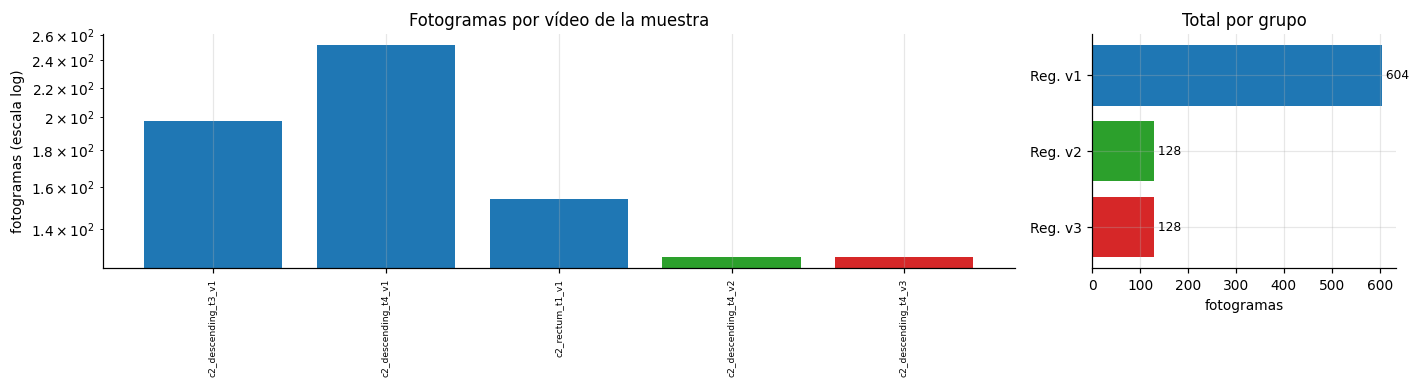

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [3, 1]})
orden = videos.sort_values(["grupo", "nombre"])
axs[0].bar(range(len(orden)), orden.n_rgb, color=[COLOR_GRUPO.get(g, "gray") for g in orden.grupo])
axs[0].set_yscale("log"); axs[0].set_ylabel("fotogramas (escala log)")
axs[0].set_xticks(range(len(orden))); axs[0].set_xticklabels(orden.nombre, rotation=90, fontsize=6)
axs[0].set_title("Fotogramas por vídeo de la muestra")
tot = videos.groupby("grupo").n_rgb.sum().reindex([g for g in ORDEN_GRUPOS if g in set(videos.grupo)])
axs[1].barh(tot.index, tot.values, color=[COLOR_GRUPO[g] for g in tot.index])
axs[1].invert_yaxis(); axs[1].set_xlabel("fotogramas"); axs[1].set_title("Total por grupo")
for g, n in tot.items():
    axs[1].text(n, g, f" {n:,}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Nota sobre la integridad.** Los cinco vídeos aparecen como inconsistentes por dos motivos que no indican archivos dañados (no se encontró ninguno). Primero, cada vídeo tiene un mapa de flujo óptico menos que fotogramas, lo cual es coherente con su definición: el flujo se calcula del fotograma actual al anterior, y el primer fotograma no tiene anterior. Segundo, no se encontraron mapas de oclusión con el nombre documentado (`occlusions/NNNN_occlusion.tiff`) en estos archivos, por lo que la fracción ocluida no se reporta en 4.12. Las demás cuentas (RGB, profundidad, normales, difusa y poses) coinciden en todos los vídeos.

### 4.4 Galería de fotogramas

Una inspección visual antes de las estadísticas: cinco fotogramas equiespaciados de un vídeo de cada grupo y, para un mismo segmento del fantoma, las tres versiones registradas. v2 y v3 comparten trayectoria, de modo que el mismo índice de fotograma muestra la misma vista sin y con residuos; v1 sigue una trayectoria distinta.

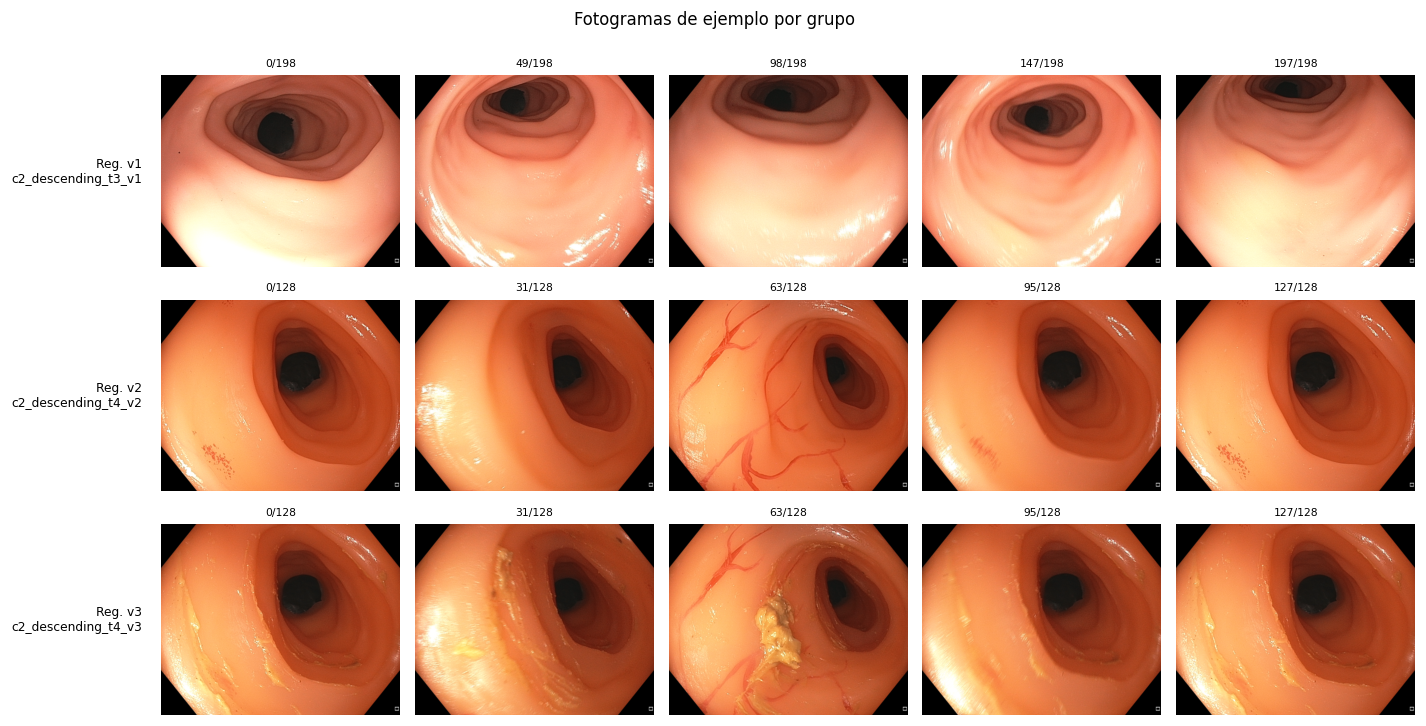

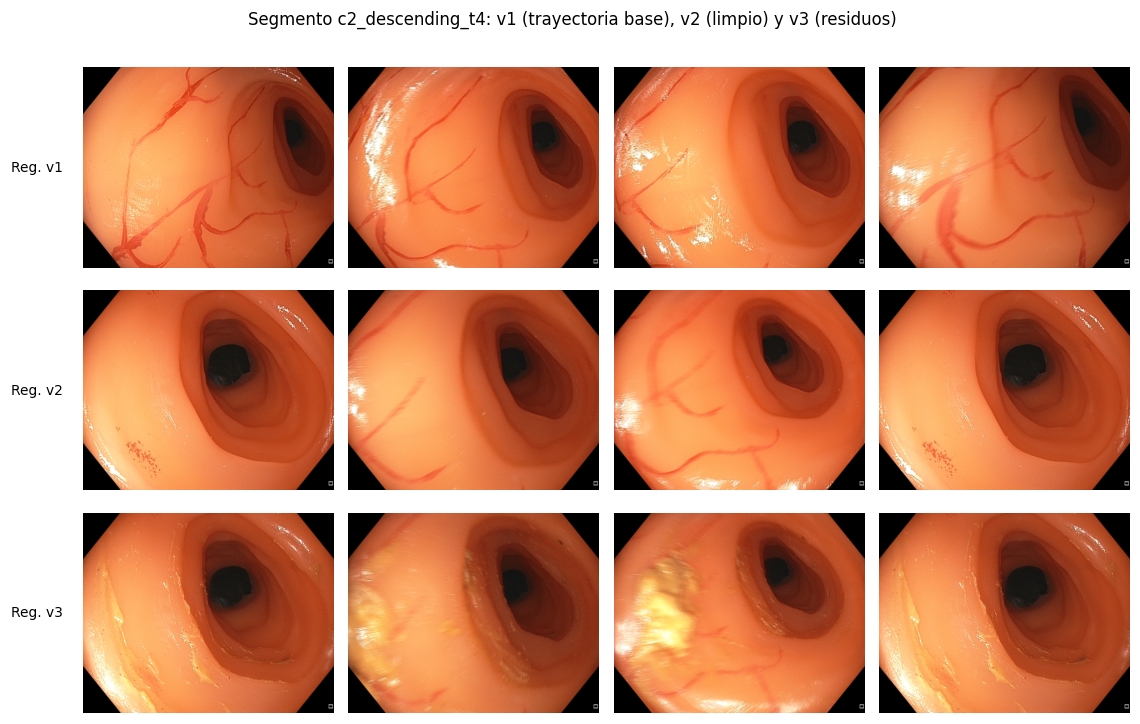

In [12]:
grupos_v = [g for g in ORDEN_GRUPOS if g in set(videos.grupo)]
fig, axs = ejes(len(grupos_v), 5, ancho=2.6, alto=2.2)
for i, g in enumerate(grupos_v):
    v = videos[videos.grupo == g].iloc[0]
    rutas = listar_fotogramas(v.carpeta)
    for j, k in enumerate(np.linspace(0, len(rutas) - 1, 5).astype(int)):
        axs[i, j].imshow(leer_rgb(rutas[k], 470)); axs[i, j].axis("off")
        axs[i, j].set_title(f"{k}/{len(rutas)}", fontsize=7)
    axs[i, 0].text(-0.08, 0.5, f"{g}\n{v.nombre}", transform=axs[i, 0].transAxes,
                   ha="right", va="center", fontsize=8)
fig.suptitle("Fotogramas de ejemplo por grupo", y=1.0); plt.tight_layout(); plt.show()

completos = [s for s, gs in videos[videos.categoria == "registrado"].groupby("segmento").grupo
             if {"Reg. v1", "Reg. v2", "Reg. v3"} <= set(gs)]
if completos:
    seg = completos[0]
    fig, axs = ejes(3, 4, ancho=2.6, alto=2.2)
    for i, ver in enumerate(["Reg. v1", "Reg. v2", "Reg. v3"]):
        rutas = listar_fotogramas(videos[(videos.segmento == seg) & (videos.grupo == ver)].iloc[0].carpeta)
        for j, q in enumerate([0.1, 0.35, 0.6, 0.85]):
            axs[i, j].imshow(leer_rgb(rutas[int(q * (len(rutas) - 1))], 470)); axs[i, j].axis("off")
        axs[i, 0].text(-0.08, 0.5, ver, transform=axs[i, 0].transAxes, ha="right", va="center")
    fig.suptitle(f"Segmento {seg}: v1 (trayectoria base), v2 (limpio) y v3 (residuos)", y=1.0)
    plt.tight_layout(); plt.show()

### 4.5 Cálculo de estadísticas por fotograma

Para cada vídeo se toman `N_FOTOGRAMAS` fotogramas equiespaciados. Con ellos se estima primero la máscara del FOV (la región conexa más grande cuyo percentil 95 de luminancia supera `UMBRAL_FOV`, con los huecos rellenados) y después, solo dentro de esa máscara, las métricas de la Tabla 4. La luminancia es $Y = 0.299R + 0.587G + 0.114B$.

**Tabla 4.** Métricas calculadas por fotograma.

| Métrica | Definición | Qué indica |
|---|---|---|
| `R`, `G`, `B` | Media de cada canal | Balance de color |
| `brillo` | Media de $Y$ | Exposición global |
| `contraste` | Desviación estándar de $Y$ | Rango tonal (contraste RMS) |
| `entropia` | $-\sum_k p_k \log_2 p_k$ del histograma de $Y$ | Cantidad de información tonal (máx. 8 bits) |
| `saturacion` | Media del canal S en HSV | Pureza del color |
| `colorido` | Métrica de Hasler y Süsstrunk [5] sobre $R-G$ y $\tfrac{1}{2}(R+G)-B$ | Riqueza cromática percibida |
| `nitidez` | Varianza del laplaciano de $Y$ [4] | Enfoque; valores bajos indican desenfoque por movimiento |
| `frac_especular` | Fracción con $V \ge 235$ y $S \le 40$ | Reflejos especulares (blancos y saturados) |
| `frac_saturado` | Fracción con algún canal $\ge 250$ | Sobreexposición |
| `frac_oscuro` | Fracción con $Y < 25$ | Subexposición, lumen lejano |

En la misma pasada se acumulan, por grupo, los histogramas de cada canal y del tono, y el espectro de potencia radial. La nitidez depende de la resolución, así que solo es comparable entre fotogramas procesados con el mismo `ANCHO`.

In [13]:
ruta_cache = os.path.join(RUTA_SALIDA, "eda_cache_imagenes.pkl")
clave = (tuple(videos.nombre), N_FOTOGRAMAS, ANCHO, UMBRAL_FOV)
cache = pd.read_pickle(ruta_cache) if REUSAR_CACHE and os.path.exists(ruta_cache) else None

if cache is None or cache.get("clave") != clave:
    registros, imagenes_video = [], {}
    acum = {g: dict(hist_rgb=np.zeros((3, 256)), hist_h=np.zeros(180), espectro=[]) for g in ORDEN_GRUPOS}
    for k, v in videos.iterrows():
        rutas = listar_fotogramas(v.carpeta)
        if not rutas:
            continue
        idx = np.unique(np.linspace(0, len(rutas) - 1, min(N_FOTOGRAMAS, len(rutas))).astype(int))
        imgs = [leer_rgb(rutas[i]) for i in idx]
        pila = np.stack(imgs).astype(np.float32)
        p95 = np.percentile(pila.mean(axis=3), 95, axis=0).astype(np.float32)
        fov = calcular_fov(p95)
        imagenes_video[v.nombre] = dict(media=pila.mean(axis=0).astype(np.uint8),
                                        desv=pila.std(axis=0).mean(axis=2), fov=fov)
        a = acum[v.grupo]
        for i, img in zip(idx, imgs):
            reg = metricas_fotograma(img, fov)
            reg.update(nombre=v.nombre, grupo=v.grupo, categoria=v.categoria, segmento=v.segmento,
                       indice=int(i), t_rel=i / max(len(rutas) - 1, 1))
            registros.append(reg)
            px = img[fov]
            for c in range(3):
                a["hist_rgb"][c] += np.bincount(px[:, c], minlength=256)
            hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[fov]
            sel = (hsv[:, 1] > 30) & (hsv[:, 2] > 30)          # el tono solo tiene sentido con color
            a["hist_h"] += np.bincount(hsv[sel, 0], minlength=180)[:180]
            a["espectro"].append(espectro_radial(gris(img)))
        print(f"[{k + 1}/{len(videos)}] {v.nombre}: {len(idx)} fotogramas")
    cache = dict(clave=clave, stats=pd.DataFrame(registros), acum=acum, imagenes=imagenes_video)
    pd.to_pickle(cache, ruta_cache)
else:
    print("Usando estadísticas guardadas en", ruta_cache)

stats, acum, imagenes_video = cache["stats"], cache["acum"], cache["imagenes"]
grupos = [g for g in ORDEN_GRUPOS if g in set(stats.grupo)]
stats["chrom_r"] = stats.R / (stats.R + stats.G + stats.B)
stats["chrom_g"] = stats.G / (stats.R + stats.G + stats.B)
print(f"{len(stats):,} fotogramas analizados en {stats.nombre.nunique()} vídeos")
display(stats.groupby("grupo")[METRICAS].describe().T.round(3).loc[(slice(None), ["mean", "std", "50%"]), grupos])

[1/5] c2_descending_t3_v1: 60 fotogramas
[2/5] c2_descending_t4_v1: 60 fotogramas
[3/5] c2_descending_t4_v2: 60 fotogramas
[4/5] c2_descending_t4_v3: 60 fotogramas
[5/5] c2_rectum_t1_v1: 60 fotogramas
300 fotogramas analizados en 5 vídeos


grupo                Reg. v1  Reg. v2  Reg. v3
brillo         mean  140.312  129.173  126.779
               std    20.064    5.458    5.561
               50%   132.456  128.814  126.592
contraste      mean   54.169   49.468   52.280
               std    11.456    4.166    3.793
               50%    50.891   50.202   52.330
entropia       mean    7.359    7.397    7.501
               std     0.231    0.110    0.076
               50%     7.418    7.368    7.473
saturacion     mean  134.280  179.034  175.841
               std    32.975    3.491    2.600
               50%   121.198  178.155  176.044
colorido       mean   61.261   77.075   74.139
               std    15.397    2.745    3.105
               50%    65.198   76.808   74.546
nitidez        mean  388.855  213.212  204.264
               std   352.101   95.813   89.227
               50%   258.971  185.155  159.098
frac_especular mean    0.030    0.005    0.005
               std     0.041    0.006    0.007
               50%     0.012    0.003    0.005
frac_saturado  mean    0.268    0.249    0.209
               std     0.180    0.064    0.062
               50%     0.250    0.257    0.214
frac_oscuro    mean    0.016    0.024    0.025
               std     0.004    0.004    0.005
               50%     0.016    0.026    0.027

### 4.6 Formación de la imagen: campo de visión, viñeteo e iluminación

La imagen media de un vídeo elimina el contenido particular de cada fotograma y deja ver lo que es constante: la forma del FOV, el viñeteo de la óptica y el patrón promedio de iluminación. El perfil radial de luminancia (media en anillos concéntricos alrededor del centro del FOV) resume ese patrón en una curva. Con una fuente de luz junto a la cámara, se espera que el centro (lumen lejano) sea más oscuro que la periferia (pared cercana) cuando la cámara mira a lo largo del colon, y lo contrario en vistas de frente a la pared.

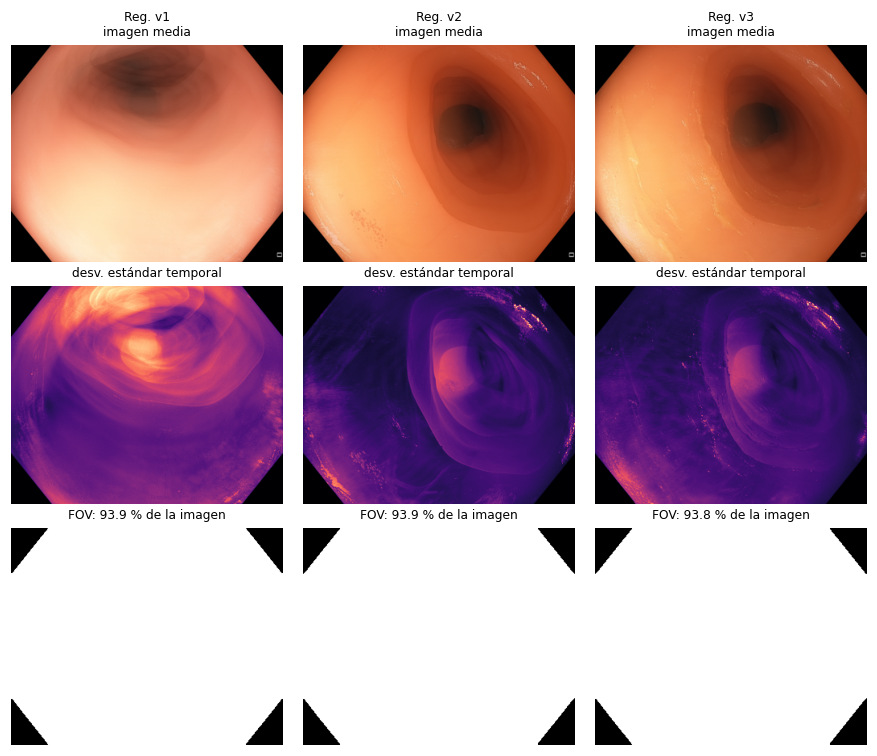

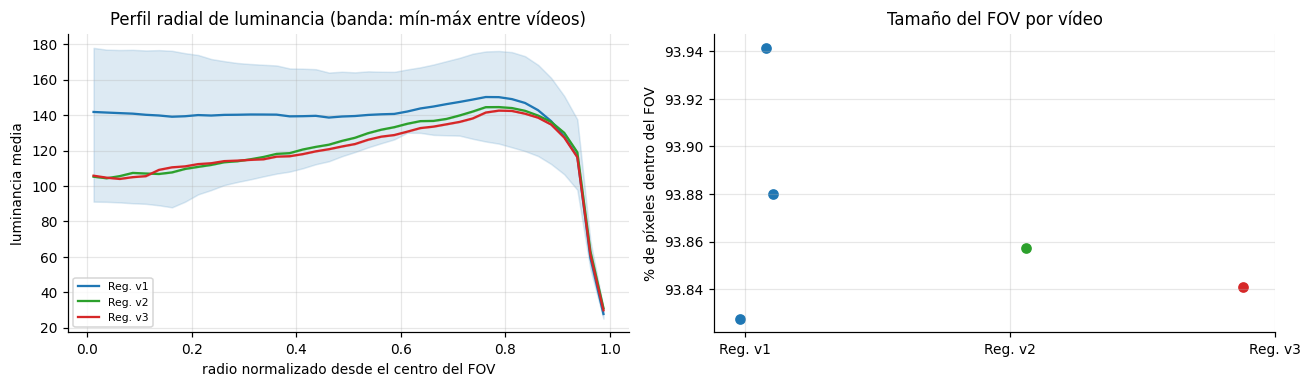

In [14]:
def perfil_radial(img_gris, fov, n=40):
    yy, xx = np.nonzero(fov)
    Y, X = np.indices(fov.shape)
    r = np.hypot(Y - yy.mean(), X - xx.mean())
    r = r / r[fov].max()
    idx = np.clip(np.digitize(r[fov], np.linspace(0, 1, n + 1)) - 1, 0, n - 1)
    return np.bincount(idx, weights=img_gris[fov], minlength=n) / np.maximum(np.bincount(idx, minlength=n), 1)

fig, axs = ejes(3, len(grupos), ancho=2.7, alto=2.3)
for j, g in enumerate(grupos):
    iv = imagenes_video[stats.loc[stats.grupo == g, "nombre"].iloc[0]]
    axs[0, j].imshow(iv["media"]); axs[0, j].set_title(f"{g}\nimagen media", fontsize=8)
    im = axs[1, j].imshow(iv["desv"], cmap="magma"); axs[1, j].set_title("desv. estándar temporal", fontsize=8)
    axs[2, j].imshow(iv["fov"], cmap="gray"); axs[2, j].set_title(f"FOV: {iv['fov'].mean() * 100:.1f} % de la imagen", fontsize=8)
    for i in range(3):
        axs[i, j].axis("off")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
radios = (np.arange(40) + 0.5) / 40
for g in grupos:
    perf = np.array([perfil_radial(gris(imagenes_video[n]["media"]).astype(float), imagenes_video[n]["fov"])
                     for n in stats.loc[stats.grupo == g, "nombre"].unique()])
    axs[0].plot(radios, perf.mean(0), color=COLOR_GRUPO[g], label=g)
    axs[0].fill_between(radios, perf.min(0), perf.max(0), color=COLOR_GRUPO[g], alpha=0.15)
axs[0].set_xlabel("radio normalizado desde el centro del FOV"); axs[0].set_ylabel("luminancia media")
axs[0].set_title("Perfil radial de luminancia (banda: mín-máx entre vídeos)"); axs[0].legend(fontsize=7)

fov_tab = pd.DataFrame([dict(nombre=n, grupo=stats.loc[stats.nombre == n, "grupo"].iloc[0],
                             fov_pct=100 * iv["fov"].mean()) for n, iv in imagenes_video.items()])
for i, g in enumerate(grupos):
    vals = fov_tab[fov_tab.grupo == g].fov_pct
    axs[1].scatter(np.full(len(vals), i) + rng_eda.uniform(-0.15, 0.15, len(vals)), vals, color=COLOR_GRUPO[g])
axs[1].set_xticks(range(len(grupos))); axs[1].set_xticklabels(grupos)
axs[1].set_ylabel("% de píxeles dentro del FOV"); axs[1].set_title("Tamaño del FOV por vídeo")
plt.tight_layout(); plt.show()

### 4.7 Color

Los histogramas por canal y de tono muestran la distribución de color de cada grupo (normalizada para que los grupos de distinto tamaño sean comparables). El diagrama de cromaticidad $r = R/(R+G+B)$, $g = G/(R+G+B)$ separa el color de la intensidad: dos fotogramas con el mismo tono pero distinta iluminación caen en el mismo punto. Se espera un predominio fuerte del rojo, propio del tejido simulado, y que v3 se desplace hacia tonos marrones y amarillos por los residuos.

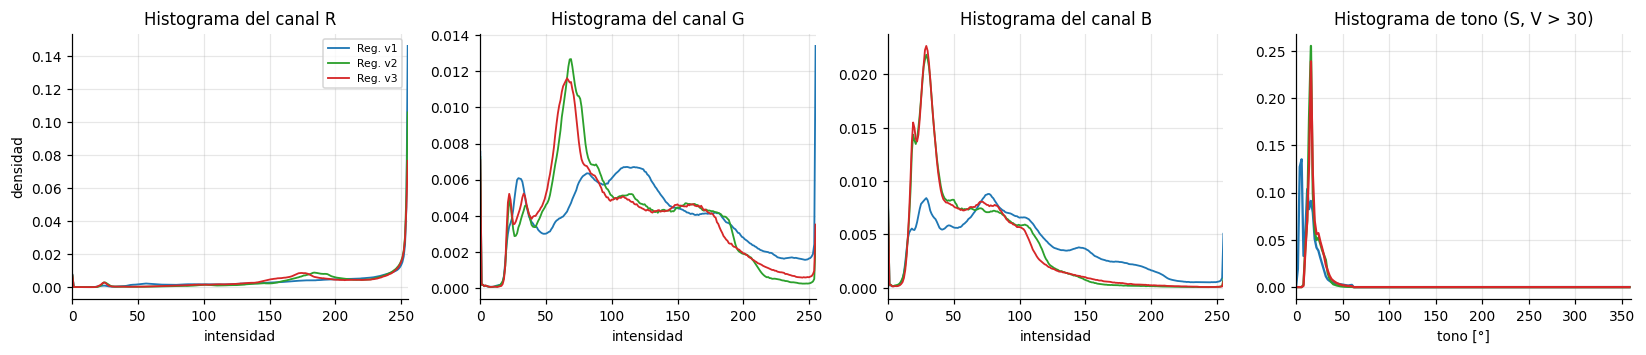

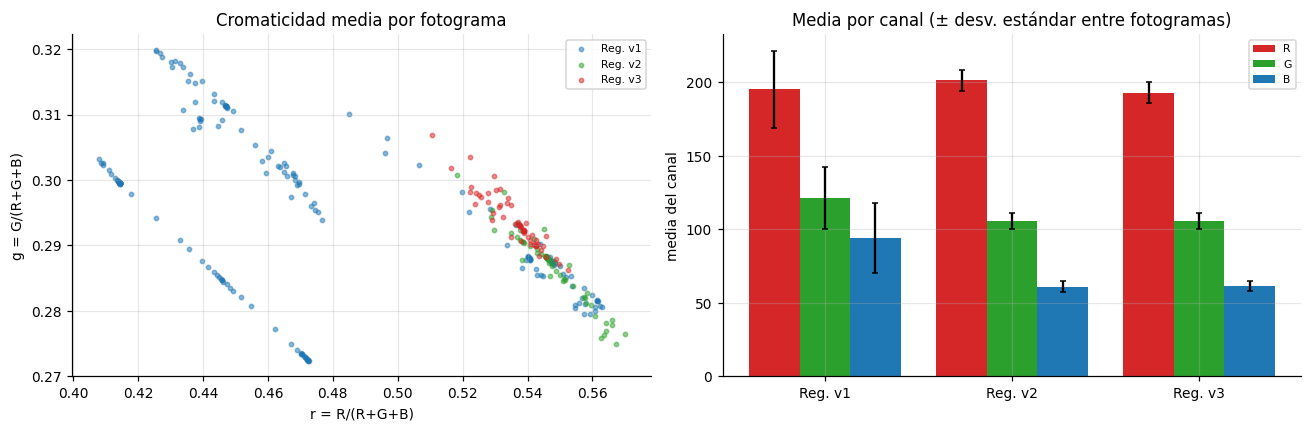

R                      G                B       saturacion  \
               mean        std        mean   std       mean   std       mean   
grupo                                                                          
Reg. v1  195.199997  26.299999  121.300003  21.0  94.099998  24.1      134.3   
Reg. v2  201.399994   7.000000  105.599998   5.8  61.000000   3.8      179.0   
Reg. v3  192.899994   7.200000  105.800003   5.6  61.400002   3.6      175.8   

              colorido        
          std     mean   std  
grupo                         
Reg. v1  33.0     61.3  15.4  
Reg. v2   3.5     77.1   2.7  
Reg. v3   2.6     74.1   3.1

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.3))
for c, (nom, ax) in enumerate(zip(["R", "G", "B"], axs[:3])):
    for g in grupos:
        h = acum[g]["hist_rgb"][c]
        ax.plot(h / h.sum(), color=COLOR_GRUPO[g], label=g, lw=1.2)
    ax.set_title(f"Histograma del canal {nom}"); ax.set_xlabel("intensidad"); ax.set_xlim(0, 255)
axs[0].set_ylabel("densidad"); axs[0].legend(fontsize=7)
for g in grupos:
    h = acum[g]["hist_h"]
    axs[3].plot(np.arange(180) * 2, h / max(h.sum(), 1), color=COLOR_GRUPO[g])
axs[3].set_title("Histograma de tono (S, V > 30)"); axs[3].set_xlabel("tono [°]"); axs[3].set_xlim(0, 360)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for g in grupos:
    s = stats[stats.grupo == g]
    axs[0].scatter(s.chrom_r, s.chrom_g, s=8, alpha=0.5, color=COLOR_GRUPO[g], label=g)
axs[0].set_xlabel("r = R/(R+G+B)"); axs[0].set_ylabel("g = G/(R+G+B)")
axs[0].set_title("Cromaticidad media por fotograma"); axs[0].legend(fontsize=7)
medias = stats.groupby("grupo")[["R", "G", "B"]].mean().reindex(grupos)
desv = stats.groupby("grupo")[["R", "G", "B"]].std().reindex(grupos)
x = np.arange(len(grupos))
for c, col in enumerate(["#d62728", "#2ca02c", "#1f77b4"]):
    axs[1].bar(x + (c - 1) * 0.27, medias.iloc[:, c], 0.27, yerr=desv.iloc[:, c], color=col,
               label=medias.columns[c], capsize=2)
axs[1].set_xticks(x); axs[1].set_xticklabels(grupos); axs[1].set_ylabel("media del canal")
axs[1].set_title("Media por canal (± desv. estándar entre fotogramas)"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

display(stats.groupby("grupo")[["R", "G", "B", "saturacion", "colorido"]].agg(["mean", "std"]).reindex(grupos).round(1))

### 4.8 Brillo, contraste y calidad de imagen

Los diagramas de caja comparan la distribución de cada métrica entre grupos. Las series de tiempo muestran cómo evolucionan dentro de un vídeo: caídas de nitidez señalan movimiento rápido, y picos de reflejos especulares coinciden con vistas de frente a la pared. Al final se muestran los fotogramas más extremos de la muestra, que ilustran las degradaciones que un modelo de eliminación de artefactos tendrá que tolerar.

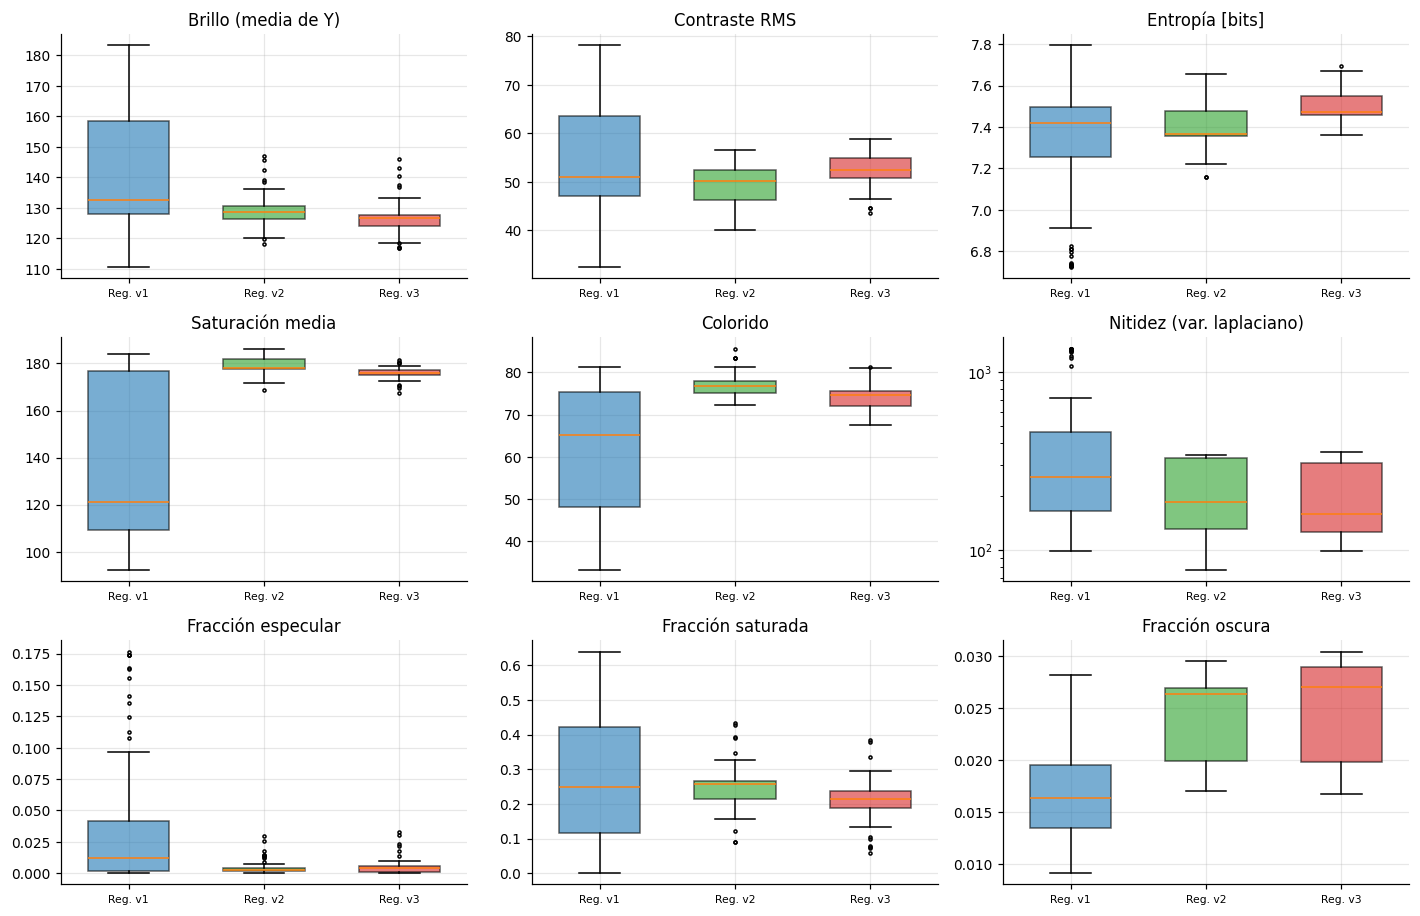

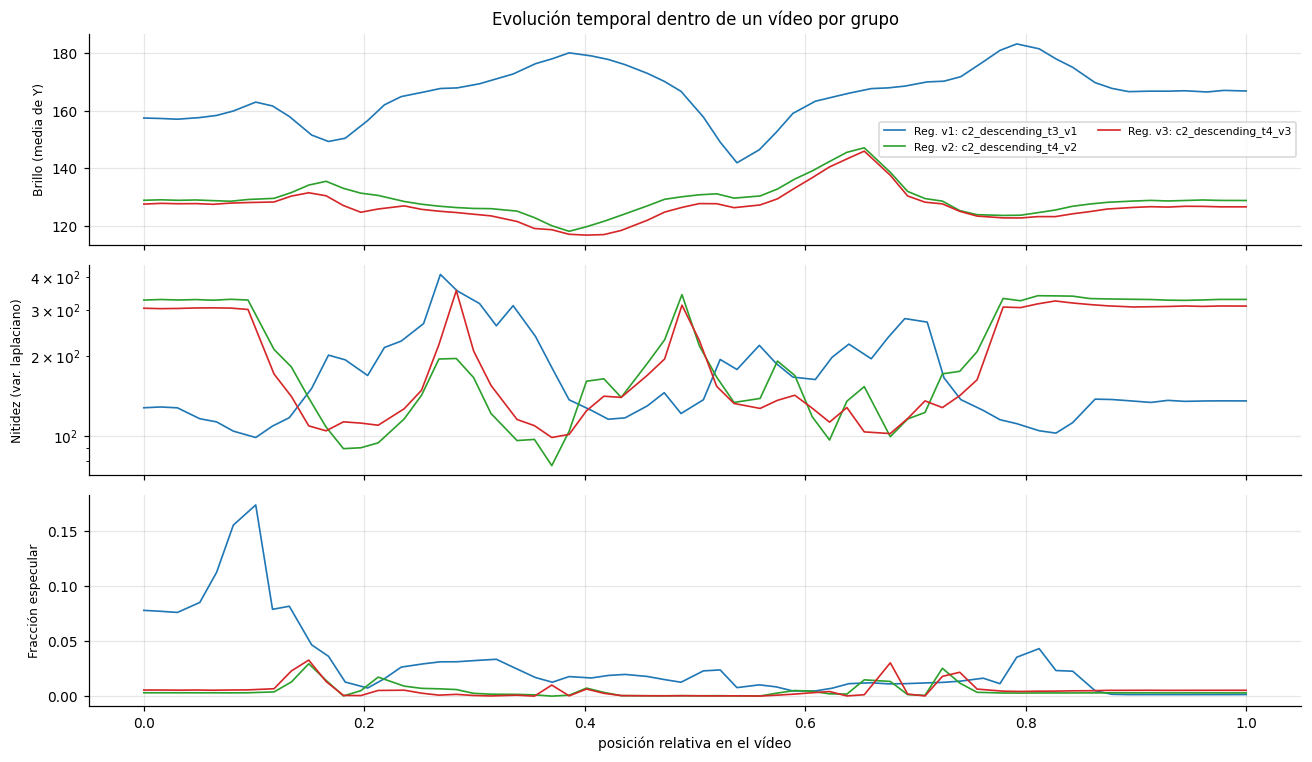

In [16]:
titulos = {"brillo": "Brillo (media de Y)", "contraste": "Contraste RMS", "entropia": "Entropía [bits]",
           "saturacion": "Saturación media", "colorido": "Colorido", "nitidez": "Nitidez (var. laplaciano)",
           "frac_especular": "Fracción especular", "frac_saturado": "Fracción saturada", "frac_oscuro": "Fracción oscura"}
fig, axs = ejes(3, 3, ancho=4.3, alto=2.8)
for ax, m in zip(axs.ravel(), METRICAS):
    datos = [stats.loc[stats.grupo == g, m].values for g in grupos]
    bp = ax.boxplot(datos, patch_artist=True, widths=0.6, showfliers=True, flierprops=dict(markersize=2))
    for caja, g in zip(bp["boxes"], grupos):
        caja.set_facecolor(COLOR_GRUPO[g]); caja.set_alpha(0.6)
    ax.set_xticks(range(1, len(grupos) + 1)); ax.set_xticklabels(grupos, fontsize=7)
    ax.set_title(titulos[m])
    if m == "nitidez":
        ax.set_yscale("log")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for g in grupos:
    nom = stats.loc[stats.grupo == g, "nombre"].iloc[0]
    s = stats[stats.nombre == nom].sort_values("t_rel")
    for ax, m in zip(axs, ["brillo", "nitidez", "frac_especular"]):
        ax.plot(s.t_rel, s[m], color=COLOR_GRUPO[g], label=f"{g}: {nom}", lw=1.1)
for ax, m in zip(axs, ["brillo", "nitidez", "frac_especular"]):
    ax.set_ylabel(titulos[m], fontsize=8)
axs[1].set_yscale("log"); axs[0].legend(fontsize=7, ncol=2)
axs[-1].set_xlabel("posición relativa en el vídeo"); axs[0].set_title("Evolución temporal dentro de un vídeo por grupo")
plt.tight_layout(); plt.show()

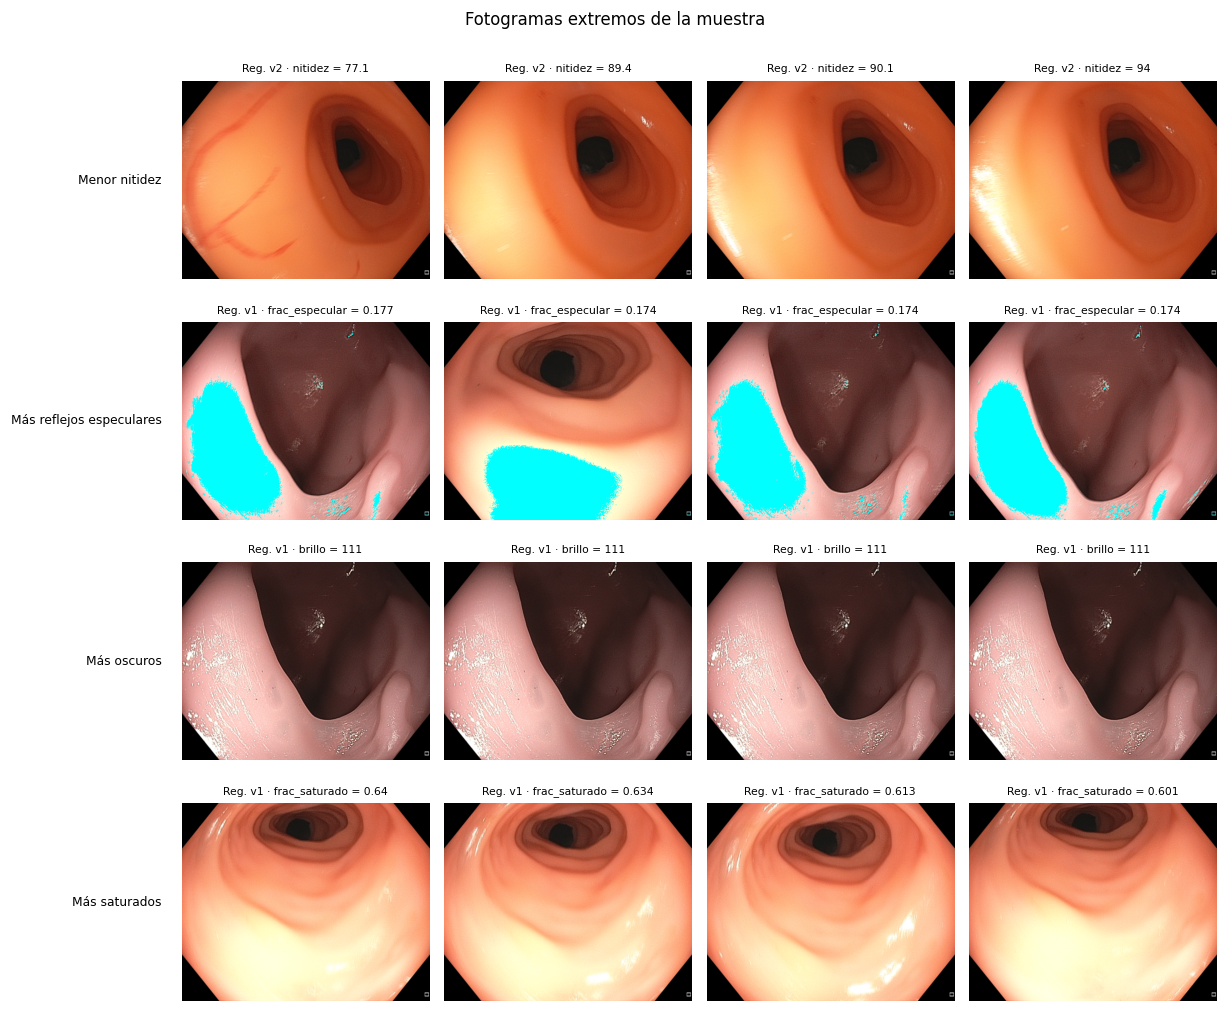

In [17]:
carpeta_de = dict(zip(videos.nombre, videos.carpeta))
def fotograma(nombre, indice, ancho=470):
    return leer_rgb(listar_fotogramas(carpeta_de[nombre])[indice], ancho)

casos = [("nitidez", True, "Menor nitidez"), ("frac_especular", False, "Más reflejos especulares"),
         ("brillo", True, "Más oscuros"), ("frac_saturado", False, "Más saturados")]
fig, axs = ejes(len(casos), 4, ancho=2.8, alto=2.3)
for i, (m, asc, titulo) in enumerate(casos):
    for j, (_, f) in enumerate(stats.sort_values(m, ascending=asc).head(4).iterrows()):
        img = fotograma(f.nombre, f.indice)
        if m == "frac_especular":
            img = img.copy(); img[mascara_especular(img)] = (0, 255, 255)   # reflejos en cian
        axs[i, j].imshow(img); axs[i, j].axis("off")
        axs[i, j].set_title(f"{f.grupo} · {m} = {f[m]:.3g}", fontsize=7)
    axs[i, 0].text(-0.08, 0.5, titulo, transform=axs[i, 0].transAxes, ha="right", va="center", fontsize=8)
fig.suptitle("Fotogramas extremos de la muestra", y=1.0); plt.tight_layout(); plt.show()

### 4.9 Contenido frecuencial

El espectro de potencia promediado radialmente indica cómo se reparte la energía de la imagen entre estructuras grandes (frecuencias bajas) y detalle fino o ruido (frecuencias altas). En imágenes naturales sigue aproximadamente una ley de potencias $P(f) \propto f^{-\alpha}$, una recta en escala log-log. Un realce de bordes más intenso eleva la cola de altas frecuencias, y el desenfoque por movimiento la reduce.

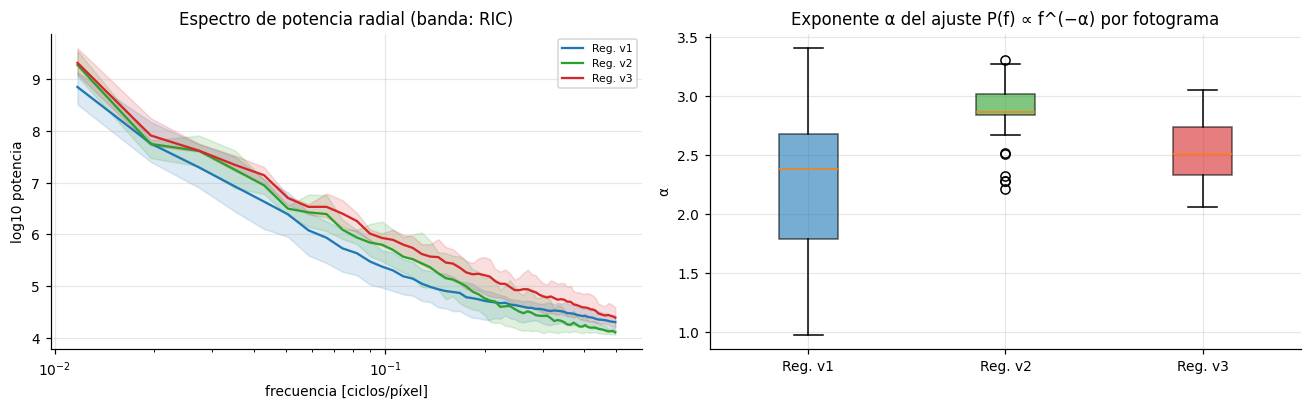

In [18]:
frec = (np.arange(64) + 0.5) / 64 * 0.5
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
pendientes = {}
for g in grupos:
    E = np.log10(np.array(acum[g]["espectro"]) + 1e-9)
    axs[0].plot(frec[1:], E.mean(0)[1:], color=COLOR_GRUPO[g], label=g)
    axs[0].fill_between(frec[1:], np.percentile(E, 25, 0)[1:], np.percentile(E, 75, 0)[1:], color=COLOR_GRUPO[g], alpha=0.15)
    sel = (frec > 0.02) & (frec < 0.4)
    pendientes[g] = [-np.polyfit(np.log10(frec[sel]), e[sel], 1)[0] for e in E]
axs[0].set_xscale("log"); axs[0].set_xlabel("frecuencia [ciclos/píxel]"); axs[0].set_ylabel("log10 potencia")
axs[0].set_title("Espectro de potencia radial (banda: RIC)"); axs[0].legend(fontsize=7)
bp = axs[1].boxplot([pendientes[g] for g in grupos], patch_artist=True)
for caja, g in zip(bp["boxes"], grupos):
    caja.set_facecolor(COLOR_GRUPO[g]); caja.set_alpha(0.6)
axs[1].set_xticks(range(1, len(grupos) + 1)); axs[1].set_xticklabels(grupos)
axs[1].set_ylabel("α"); axs[1].set_title("Exponente α del ajuste P(f) ∝ f^(−α) por fotograma")
plt.tight_layout(); plt.show()

### 4.10 Relaciones entre métricas y separabilidad de los grupos

La matriz de correlación de Spearman muestra qué métricas aportan información redundante. El análisis de componentes principales (PCA) sobre las métricas estandarizadas proyecta cada fotograma en dos dimensiones: si los grupos forman nubes separadas, existe un cambio de dominio entre ellos que el modelo tendrá que cubrir (por ejemplo, entrenar en vídeos registrados y aplicar en cribado).

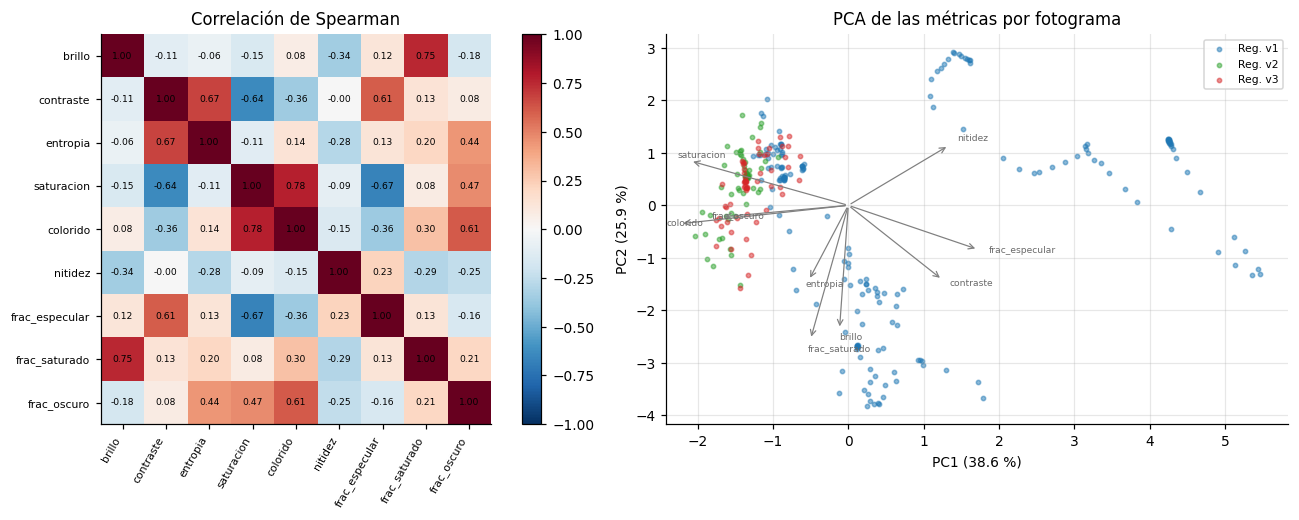

,PC1,PC2,PC3
brillo,-0.03,-0.54,0.40
contraste,0.29,-0.32,-0.49
entropia,-0.12,-0.33,-0.58
saturacion,-0.48,0.19,-0.15
colorido,-0.51,-0.08,-0.03
nitidez,0.31,0.26,-0.22
frac_especular,0.39,-0.19,-0.17
frac_saturado,-0.12,-0.59,0.17
frac_oscuro,-0.39,-0.05,-0.38


In [19]:
X = stats[METRICAS].copy()
X["nitidez"] = np.log10(X["nitidez"] + 1e-6)
corr = X.corr(method="spearman")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
im = axs[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axs[0].set_xticks(range(len(METRICAS))); axs[0].set_xticklabels(METRICAS, rotation=60, ha="right", fontsize=7)
axs[0].set_yticks(range(len(METRICAS))); axs[0].set_yticklabels(METRICAS, fontsize=7)
for i in range(len(METRICAS)):
    for j in range(len(METRICAS)):
        axs[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
axs[0].grid(False); fig.colorbar(im, ax=axs[0], fraction=0.046); axs[0].set_title("Correlación de Spearman")

Z = ((X - X.mean()) / X.std(ddof=0).replace(0, 1)).values
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
var_exp = S ** 2 / (S ** 2).sum()
pcs = Z @ Vt[:2].T
for g in grupos:
    sel = (stats.grupo == g).values
    axs[1].scatter(pcs[sel, 0], pcs[sel, 1], s=8, alpha=0.5, color=COLOR_GRUPO[g], label=g)
escala_flecha = np.abs(pcs).max() * 0.8
for k, m in enumerate(METRICAS):
    axs[1].annotate("", xy=(Vt[0, k] * escala_flecha, Vt[1, k] * escala_flecha), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))
    axs[1].text(Vt[0, k] * escala_flecha * 1.08, Vt[1, k] * escala_flecha * 1.08, m, fontsize=6, color="dimgray")
axs[1].set_xlabel(f"PC1 ({var_exp[0] * 100:.1f} %)"); axs[1].set_ylabel(f"PC2 ({var_exp[1] * 100:.1f} %)")
axs[1].set_title("PCA de las métricas por fotograma"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

display(pd.DataFrame(Vt[:3].T, index=METRICAS, columns=["PC1", "PC2", "PC3"]).round(2))

### 4.11 Efecto de los residuos (v2 frente a v3)

Como v2 y v3 comparten trayectoria y parámetros de adquisición, la diferencia entre fotogramas con el mismo índice aísla el efecto de los residuos. Primero se verifica esa correspondencia comparando las posiciones de la cámara de ambos vídeos. Después, para cada par de fotogramas, se calcula la diferencia de color $\Delta E$ en el espacio CIELAB (tras un suavizado gaussiano que atenúa ruido y pequeños desalineamientos) y se marca como residuo todo píxel del FOV con $\Delta E$ mayor que `UMBRAL_DELTA_E`. Esta máscara es una aproximación: también captura reflejos que cambian entre tomas, por lo que el umbral se justifica con el histograma de $\Delta E$ y conviene validarlo visualmente con los ejemplos.

In [20]:
UMBRAL_DELTA_E = 20

def a_lab(img):
    return cv2.cvtColor(img.astype(np.float32) / 255.0, cv2.COLOR_RGB2Lab)

def delta_e(a, b, sigma=2):
    return np.linalg.norm(cv2.GaussianBlur(a_lab(a), (0, 0), sigma) - cv2.GaussianBlur(a_lab(b), (0, 0), sigma), axis=2)

def mascara_residuos(de, fov):
    m = ((de > UMBRAL_DELTA_E) & fov).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8)) > 0

regs = videos[videos.categoria == "registrado"]
pares = [s for s, gs in regs.groupby("segmento").grupo if {"Reg. v2", "Reg. v3"} <= set(gs)]
print(f"Pares v2/v3 en la muestra: {len(pares)}")

alineacion, fracciones, deltas, top = [], [], [], []
hist_de = np.zeros(100)
color_res, color_tejido = [], []
for s in pares:
    v2 = regs[(regs.segmento == s) & (regs.grupo == "Reg. v2")].iloc[0]
    v3 = regs[(regs.segmento == s) & (regs.grupo == "Reg. v3")].iloc[0]
    r2, r3 = listar_fotogramas(v2.carpeta), listar_fotogramas(v3.carpeta)
    n = min(len(r2), len(r3))
    P2, P3 = leer_poses(v2.carpeta), leer_poses(v3.carpeta)
    fila = dict(segmento=s, fotogramas_v2=len(r2), fotogramas_v3=len(r3))
    if P2 is not None and P3 is not None:
        m = min(len(P2), len(P3))
        d = np.linalg.norm(P2[:m, :3, 3] - P3[:m, :3, 3], axis=1)
        fila.update(dif_posicion_mediana=np.median(d), dif_posicion_max=d.max())
    alineacion.append(fila)
    fov = imagenes_video[v3.nombre]["fov"]
    for i in np.unique(np.linspace(0, n - 1, min(N_FOTOGRAMAS, n)).astype(int)):
        a, b = leer_rgb(r2[i]), leer_rgb(r3[i])
        de = delta_e(a, b)
        hist_de += np.histogram(de[fov], bins=100, range=(0, 100))[0]
        mres = mascara_residuos(de, fov)
        frac = mres.sum() / fov.sum()
        fracciones.append(dict(segmento=s, indice=i, t_rel=i / max(n - 1, 1), frac_residuos=frac))
        ma, mb = metricas_fotograma(a, fov), metricas_fotograma(b, fov)
        deltas.append({k: mb[k] - ma[k] for k in METRICAS} | {"segmento": s})
        top.append((frac, s, i))
        pr, pt = b[mres], b[fov & ~mres]
        if len(pr):
            color_res.append(pr[rng_eda.choice(len(pr), min(300, len(pr)), replace=False)])
        if len(pt):
            color_tejido.append(pt[rng_eda.choice(len(pt), min(300, len(pt)), replace=False)])
    print(f"  {s}: {n} fotogramas emparejados")

if pares:
    alineacion = pd.DataFrame(alineacion); fracciones = pd.DataFrame(fracciones); deltas = pd.DataFrame(deltas)
    print("Verificación de la correspondencia v2/v3 (diferencia de posición de la cámara, unidades de pose.txt):")
    display(alineacion.round(3))

Pares v2/v3 en la muestra: 1
  c2_descending_t4: 128 fotogramas emparejados
Verificación de la correspondencia v2/v3 (diferencia de posición de la cámara, unidades de pose.txt):


,segmento,fotogramas_v2,fotogramas_v3,dif_posicion_mediana,dif_posicion_max
0,c2_descending_t4,128,128,0.0,0.0


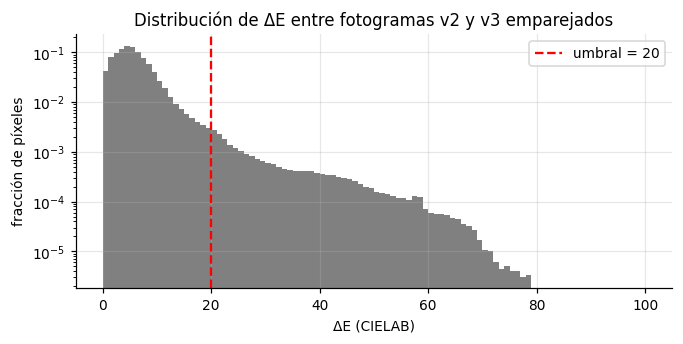

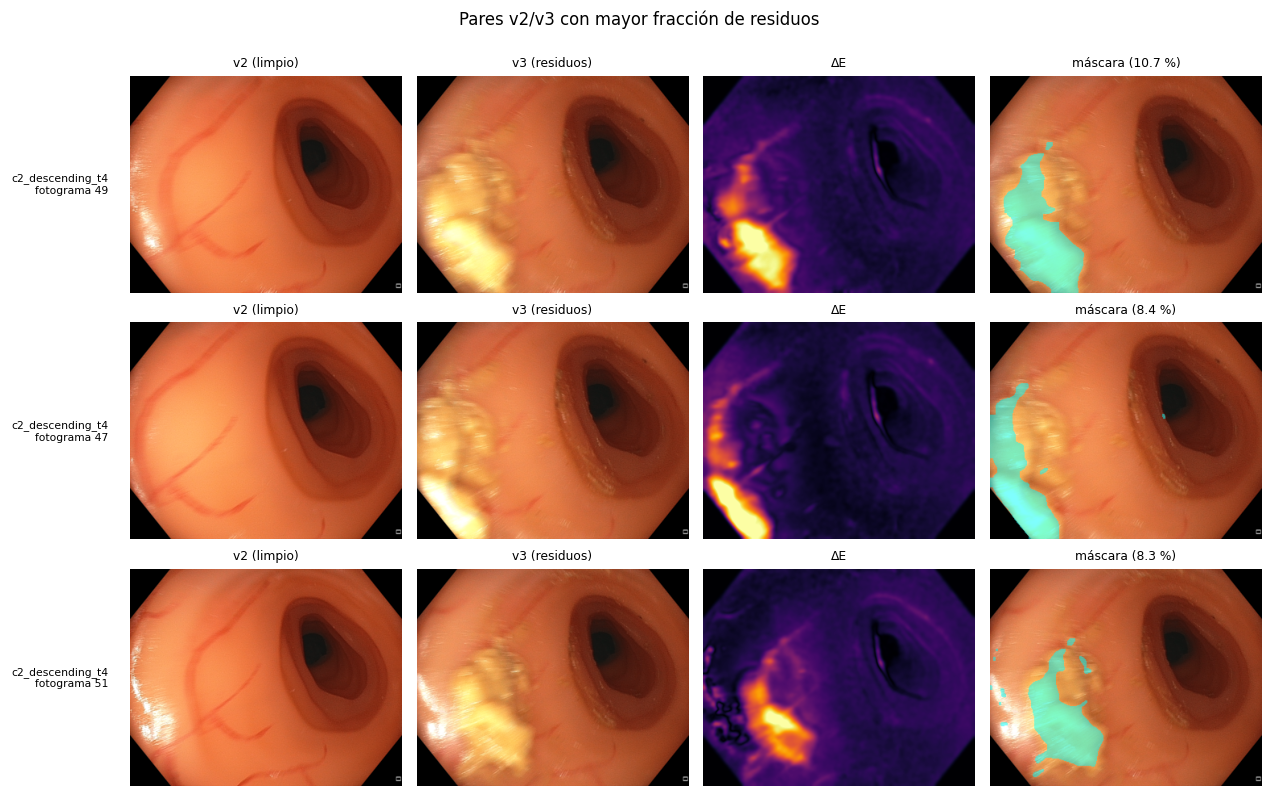

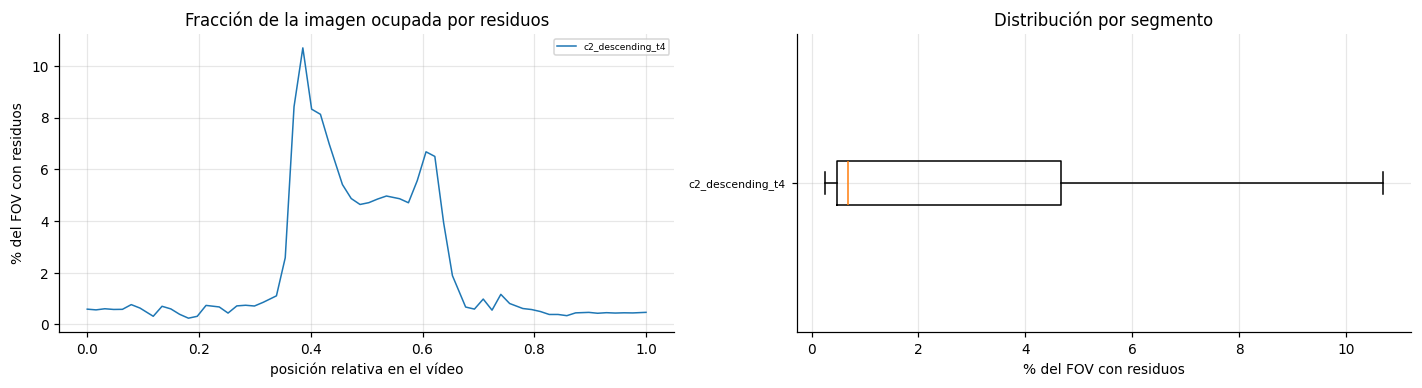

In [21]:
if pares:
    # Histograma de ΔE y ejemplos con mayor fracción de residuos
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar(np.arange(100) + 0.5, hist_de / hist_de.sum(), width=1, color="gray")
    ax.axvline(UMBRAL_DELTA_E, color="red", ls="--", label=f"umbral = {UMBRAL_DELTA_E}")
    ax.set_yscale("log"); ax.set_xlabel("ΔE (CIELAB)"); ax.set_ylabel("fracción de píxeles")
    ax.set_title("Distribución de ΔE entre fotogramas v2 y v3 emparejados"); ax.legend(); plt.show()

    fig, axs = ejes(3, 4, ancho=2.9, alto=2.4)
    for fila_ax, (frac, s, i) in zip(axs, sorted(top, reverse=True)[:3]):
        v2 = regs[(regs.segmento == s) & (regs.grupo == "Reg. v2")].iloc[0]
        v3 = regs[(regs.segmento == s) & (regs.grupo == "Reg. v3")].iloc[0]
        a, b = leer_rgb(listar_fotogramas(v2.carpeta)[i]), leer_rgb(listar_fotogramas(v3.carpeta)[i])
        de = delta_e(a, b); mres = mascara_residuos(de, imagenes_video[v3.nombre]["fov"])
        sup = b.copy(); sup[mres] = (0.5 * sup[mres] + [0, 127, 127]).astype(np.uint8)
        for ax, im, t in zip(fila_ax, [a, b, de, sup], ["v2 (limpio)", "v3 (residuos)", "ΔE", f"máscara ({frac * 100:.1f} %)"]):
            if im.ndim == 2:
                ax.imshow(im, cmap="inferno", vmin=0, vmax=60)
            else:
                ax.imshow(im)
            ax.set_title(t, fontsize=8); ax.axis("off")
        fila_ax[0].text(-0.08, 0.5, f"{s}\nfotograma {i}", transform=fila_ax[0].transAxes, ha="right", va="center", fontsize=7)
    fig.suptitle("Pares v2/v3 con mayor fracción de residuos", y=1.0); plt.tight_layout(); plt.show()

    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
    for s, d in fracciones.groupby("segmento"):
        axs[0].plot(d.t_rel, d.frac_residuos * 100, lw=1, label=s)
    axs[0].set_xlabel("posición relativa en el vídeo"); axs[0].set_ylabel("% del FOV con residuos")
    axs[0].set_title("Fracción de la imagen ocupada por residuos"); axs[0].legend(fontsize=6)
    orden_seg = fracciones.groupby("segmento").frac_residuos.median().sort_values().index
    axs[1].boxplot([fracciones.loc[fracciones.segmento == s, "frac_residuos"] * 100 for s in orden_seg], vert=False)
    axs[1].set_yticks(range(1, len(orden_seg) + 1)); axs[1].set_yticklabels(orden_seg, fontsize=7)
    axs[1].set_xlabel("% del FOV con residuos"); axs[1].set_title("Distribución por segmento")
    plt.tight_layout(); plt.show()

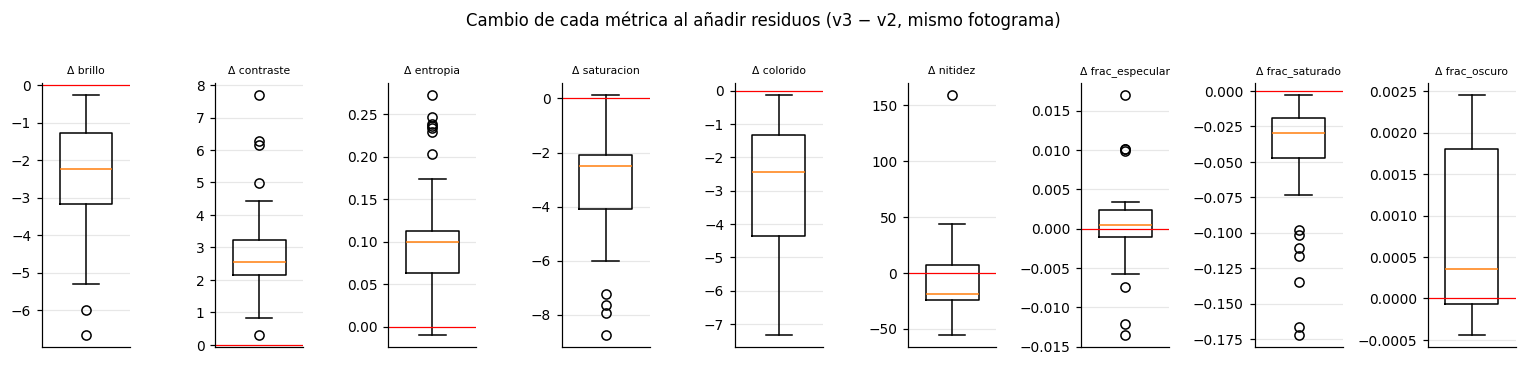

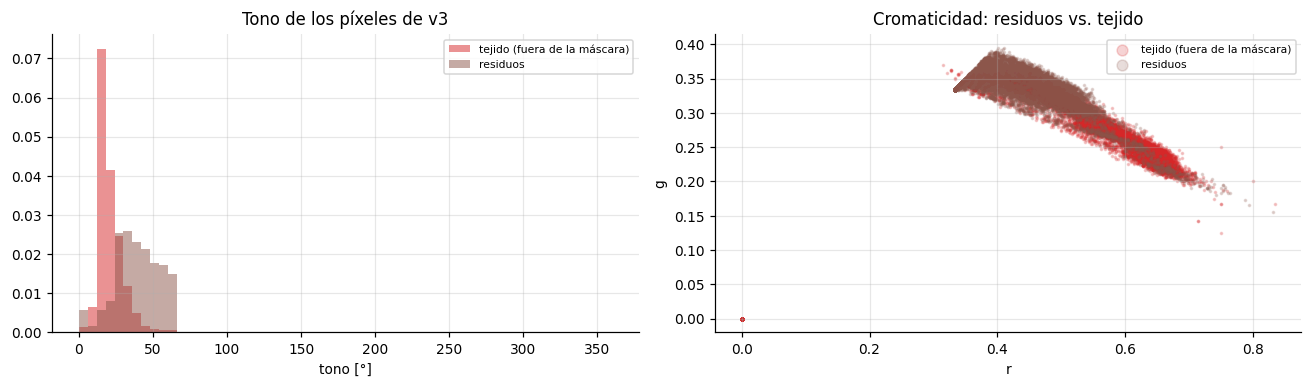

,count,mean (%),std (%),min (%),25% (%),50% (%),75% (%),max (%)
segmento,,,,,,,,
c2_descending_t4,6000.0,2.2,2.7,0.2,0.5,0.7,4.7,10.7


In [22]:
if pares:
    fig, axs = ejes(1, len(METRICAS), ancho=1.55, alto=3.2)
    for ax, m in zip(axs[0], METRICAS):
        ax.boxplot(deltas[m], widths=0.6); ax.axhline(0, color="red", lw=0.8)
        ax.set_title(f"Δ {m}", fontsize=7); ax.set_xticks([])
    fig.suptitle("Cambio de cada métrica al añadir residuos (v3 − v2, mismo fotograma)", y=1.02)
    plt.tight_layout(); plt.show()

    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    cr = np.concatenate(color_res) if color_res else np.zeros((0, 3), np.uint8)
    ct = np.concatenate(color_tejido) if color_tejido else np.zeros((0, 3), np.uint8)
    for datos, nom, col in [(ct, "tejido (fuera de la máscara)", "#d62728"), (cr, "residuos", "#8c564b")]:
        if len(datos) == 0:
            continue
        hsv = cv2.cvtColor(datos.reshape(-1, 1, 3), cv2.COLOR_RGB2HSV).reshape(-1, 3)
        axs[0].hist(hsv[:, 0] * 2, bins=60, range=(0, 360), density=True, alpha=0.5, color=col, label=nom)
        suma = datos.sum(1, keepdims=True).clip(1)
        axs[1].scatter(datos[:, 0] / suma[:, 0], datos[:, 1] / suma[:, 0], s=2, alpha=0.2, color=col, label=nom)
    axs[0].set_xlabel("tono [°]"); axs[0].set_title("Tono de los píxeles de v3"); axs[0].legend(fontsize=7)
    axs[1].set_xlabel("r"); axs[1].set_ylabel("g"); axs[1].set_title("Cromaticidad: residuos vs. tejido"); axs[1].legend(fontsize=7, markerscale=5)
    plt.tight_layout(); plt.show()

    display(fracciones.groupby("segmento").frac_residuos.describe().mul(100).round(1)
            .rename(columns=lambda c: c if c == "count" else f"{c} (%)"))

### 4.12 Mapas de referencia de los vídeos registrados

Para una submuestra de fotogramas de cada vídeo registrado se decodifican los mapas de la Tabla 3 y se analizan la distribución de profundidades y la fracción de píxeles fuera de rango (0 o 100 mm, valores recortados), la magnitud del flujo óptico, el ángulo entre la normal de la superficie y el eje óptico (0° = pared vista de frente, 90° = pared paralela a la línea de visión) y la fracción ocluida.

La relación entre luminancia y profundidad conecta las imágenes con su física: con una fuente puntual junto a la cámara, la irradiancia cae aproximadamente como $1/d^2$. Tras la curva de respuesta (gamma) de la cámara, la luminancia registrada debería seguir una ley de potencias $Y \propto d^{-k}$ con un exponente $k$ menor que 2; el ajuste en escala log-log estima $k$.

In [23]:
N_GT = 20
reg_v = videos[videos.categoria == "registrado"]
gt_filas = []
h_prof = {g: np.zeros(100) for g in grupos}
h_flujo = {g: np.zeros(80) for g in grupos}
h_ang = {g: np.zeros(90) for g in grupos}
h_lum_prof = np.zeros((100, 256))
ejemplo_gt = None

for _, v in reg_v.iterrows():
    rutas = listar_fotogramas(v.carpeta)
    fov = imagenes_video[v.nombre]["fov"]
    for i in np.unique(np.linspace(0, len(rutas) - 1, min(N_GT, len(rutas))).astype(int)):
        num = _numero(rutas[i])
        rd = ruta_modalidad(v.carpeta, "depth", num)
        if not existe(rd):
            continue
        img = leer_rgb(rutas[i]); y = gris(img)
        d = leer_profundidad(rd)
        valido = fov & (d > 0) & (d < 99.9)
        fila = dict(nombre=v.nombre, grupo=v.grupo, t_rel=i / max(len(rutas) - 1, 1),
                    prof_media=d[valido].mean() if valido.any() else np.nan,
                    frac_fuera_rango=1 - valido.sum() / fov.sum())
        h_prof[v.grupo] += np.histogram(d[valido], bins=100, range=(0, 100))[0]
        h_lum_prof += np.histogram2d(d[valido], y[valido], bins=[100, 256], range=[[0, 100], [0, 256]])[0]
        rn, rf = ruta_modalidad(v.carpeta, "normals", num), ruta_modalidad(v.carpeta, "optical_flow", num)
        ro = ruta_modalidad(v.carpeta, "occlusions", num)
        if existe(rn):
            nrm = leer_normales(rn)
            ang = np.degrees(np.arccos(np.clip(-nrm[..., 2], -1, 1)))
            fila["angulo_medio"] = ang[valido].mean() if valido.any() else np.nan
            h_ang[v.grupo] += np.histogram(ang[valido], bins=90, range=(0, 180))[0]
        if existe(rf):
            mag = np.hypot(*np.moveaxis(leer_flujo(rf), -1, 0))
            fila["flujo_medio"] = mag[fov].mean()
            h_flujo[v.grupo] += np.histogram(mag[fov], bins=80, range=(0, 20 * np.sqrt(2)))[0]
        if existe(ro):
            fila["frac_oclusion"] = leer_oclusion(ro)[fov].mean()
        gt_filas.append(fila)
        if ejemplo_gt is None and i >= len(rutas) // 2:
            ejemplo_gt = (v.carpeta, rutas[i], num, v.nombre)

gt = pd.DataFrame(gt_filas)
print(f"Mapas de referencia analizados: {len(gt)} fotogramas de {gt.nombre.nunique() if len(gt) else 0} vídeos")

Mapas de referencia analizados: 100 fotogramas de 5 vídeos


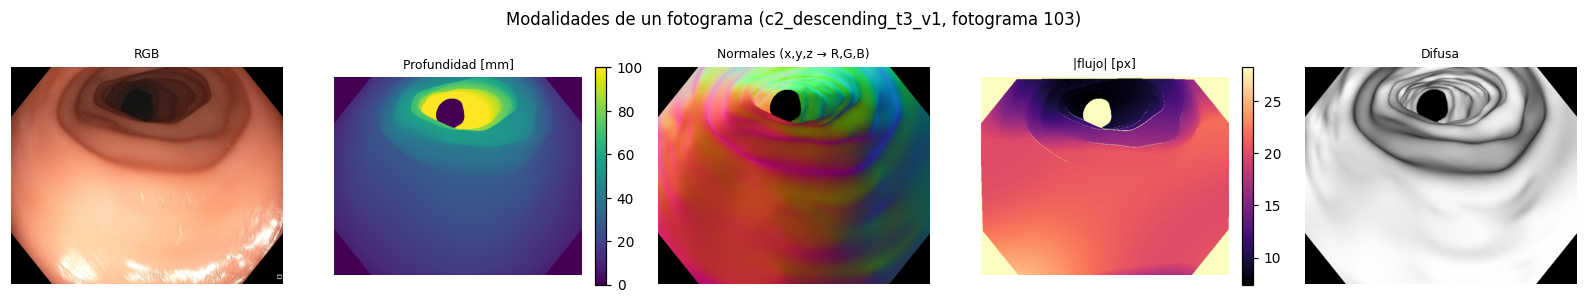

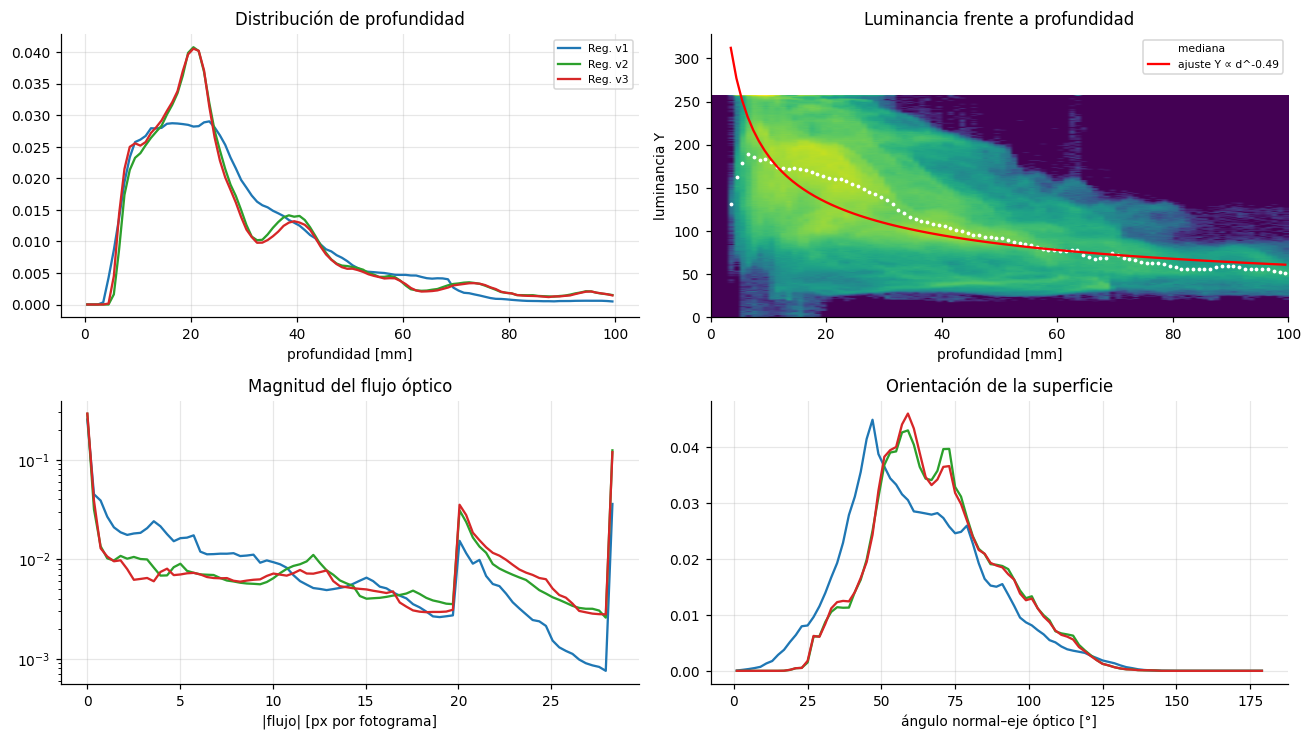

grupo                  Reg. v1  Reg. v2  Reg. v3
prof_media       mean   28.458   29.663   28.905
                 std     3.722    1.094    1.143
                 50%    27.697   30.286   29.531
frac_fuera_rango mean    0.033    0.058    0.057
                 std     0.017    0.002    0.002
                 50%     0.033    0.058    0.057
flujo_medio      mean    7.035   10.919   11.179
                 std     6.377    8.635    8.563
                 50%     5.699   11.512   13.846
angulo_medio     mean   61.746   68.814   68.322
                 std     5.333    1.282    1.244
                 50%    61.281   69.641   69.184

In [24]:
if ejemplo_gt:
    carpeta, ruta_rgb, num, nom = ejemplo_gt
    paneles = [("RGB", leer_rgb(ruta_rgb, 675), None)]
    if existe(ruta_modalidad(carpeta, "depth", num)):
        paneles.append(("Profundidad [mm]", leer_profundidad(ruta_modalidad(carpeta, "depth", num), 675), "viridis"))
    if existe(ruta_modalidad(carpeta, "normals", num)):
        paneles.append(("Normales (x,y,z → R,G,B)", (leer_normales(ruta_modalidad(carpeta, "normals", num), 675) + 1) / 2, None))
    if existe(ruta_modalidad(carpeta, "optical_flow", num)):
        paneles.append(("|flujo| [px]", np.hypot(*np.moveaxis(leer_flujo(ruta_modalidad(carpeta, "optical_flow", num), 675), -1, 0)), "magma"))
    if existe(ruta_modalidad(carpeta, "occlusions", num)):
        paneles.append(("Oclusión", leer_oclusion(ruta_modalidad(carpeta, "occlusions", num), 675), "gray"))
    if existe(ruta_modalidad(carpeta, "diffuse", num)):
        paneles.append(("Difusa", leer_difusa(ruta_modalidad(carpeta, "diffuse", num), 675), "gray"))
    fig, axs = ejes(1, len(paneles), ancho=2.9, alto=2.6)
    for ax, (t, im, cm) in zip(axs[0], paneles):
        if im.dtype == bool:
            im = im.astype(float)
        elif cm is None and im.dtype != np.uint8:
            im = np.clip(im, 0, 1)
        h = ax.imshow(im, cmap=cm)
        if cm in ("viridis", "magma"):
            fig.colorbar(h, ax=ax, fraction=0.04)
        ax.set_title(t, fontsize=8); ax.axis("off")
    fig.suptitle(f"Modalidades de un fotograma ({nom}, fotograma {num})", y=1.02); plt.tight_layout(); plt.show()

if len(gt):
    g_reg = [g for g in grupos if g.startswith("Reg.")]
    fig, axs = ejes(2, 2, ancho=6, alto=3.4)
    for g in g_reg:
        axs[0, 0].plot(np.arange(100) + 0.5, h_prof[g] / max(h_prof[g].sum(), 1), color=COLOR_GRUPO[g], label=g)
        axs[1, 0].plot(np.linspace(0, 28.3, 80), h_flujo[g] / max(h_flujo[g].sum(), 1), color=COLOR_GRUPO[g], label=g)
        axs[1, 1].plot(np.arange(90) * 2 + 1, h_ang[g] / max(h_ang[g].sum(), 1), color=COLOR_GRUPO[g], label=g)
    axs[0, 0].set_xlabel("profundidad [mm]"); axs[0, 0].set_title("Distribución de profundidad"); axs[0, 0].legend(fontsize=7)
    axs[1, 0].set_yscale("log"); axs[1, 0].set_xlabel("|flujo| [px por fotograma]"); axs[1, 0].set_title("Magnitud del flujo óptico")
    axs[1, 1].set_xlabel("ángulo normal–eje óptico [°]"); axs[1, 1].set_title("Orientación de la superficie")

    ax = axs[0, 1]
    ax.imshow(h_lum_prof.T + 1, origin="lower", aspect="auto", norm=LogNorm(), cmap="viridis", extent=[0, 100, 0, 256])
    cuentas = h_lum_prof.sum(1)
    medianas = np.array([np.searchsorted(np.cumsum(f), f.sum() / 2) if f.sum() else np.nan for f in h_lum_prof]) + 0.5
    centros = np.arange(100) + 0.5
    sel = (cuentas > 200) & (medianas > 5) & (medianas < 240) & (centros > 3)
    ax.plot(centros[cuentas > 200], medianas[cuentas > 200], "w.", ms=3, label="mediana")
    if sel.sum() >= 3:
        k, loga = np.polyfit(np.log(centros[sel]), np.log(medianas[sel]), 1)
        dd = np.linspace(centros[sel].min(), centros[sel].max(), 100)
        ax.plot(dd, np.exp(loga) * dd ** k, "r-", label=f"ajuste Y ∝ d^{k:.2f}")
    ax.set_xlabel("profundidad [mm]"); ax.set_ylabel("luminancia Y"); ax.set_title("Luminancia frente a profundidad")
    ax.legend(fontsize=7); ax.grid(False)
    plt.tight_layout(); plt.show()

    display(gt.groupby("grupo")[[c for c in ["prof_media", "frac_fuera_rango", "flujo_medio", "angulo_medio", "frac_oclusion"]
                                 if c in gt]].describe().T.loc[(slice(None), ["mean", "std", "50%"]), :].round(3))

### 4.13 Redundancia temporal

Para cada vídeo se toman `N_VENTANAS` ventanas de fotogramas consecutivos y se calcula el índice de similitud estructural (SSIM) [6] entre cada fotograma y el que está `k` posiciones adelante. La curva SSIM frente a `k` indica qué tan rápido cambia la escena: el desfase en que el SSIM mediano cae por debajo de `UMBRAL_SSIM` es una estimación del paso de submuestreo con el que los fotogramas dejan de ser casi duplicados.

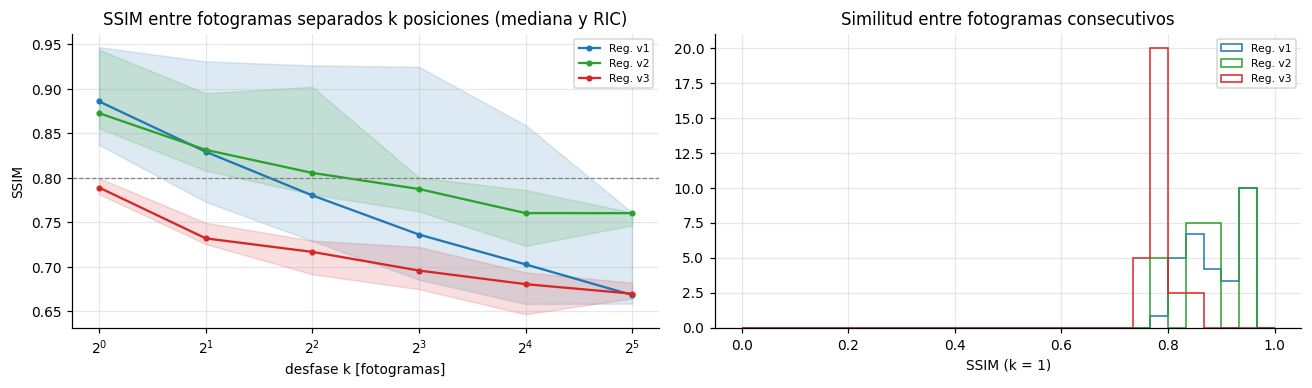

Primer desfase con SSIM mediano < 0.8: {'Reg. v1': 4, 'Reg. v2': 8, 'Reg. v3': 1}


In [27]:
DESFASES, N_VENTANAS, UMBRAL_SSIM = [1, 2, 4, 8, 16, 32], 3, 0.8
largo = max(DESFASES) + 1
filas_ssim = []
for _, v in videos.iterrows():
    rutas = listar_fotogramas(v.carpeta)
    if len(rutas) < largo:
        continue
    for s0 in rng_eda.choice(len(rutas) - largo + 1, size=min(N_VENTANAS, len(rutas) - largo + 1), replace=False):
        grises = [gris(leer_rgb(rutas[s0 + i])) for i in range(largo)]
        for k in DESFASES:
            for t in range(0, largo - k, max(1, (largo - k) // 4)):
                filas_ssim.append(dict(nombre=v.nombre, grupo=v.grupo, desfase=k,
                                       ssim=ssim(grises[t], grises[t + k], data_range=255)))
df_ssim = pd.DataFrame(filas_ssim)

if df_ssim.empty:
    print(f"Ningún vídeo tiene al menos {largo} fotogramas; se omite este análisis.")
else:

    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    pasos = {}
    for g in grupos:
        d = df_ssim[df_ssim.grupo == g].groupby("desfase").ssim
        if d.ngroups == 0:
            continue
        med, q1, q3 = d.median(), d.quantile(0.25), d.quantile(0.75)
        axs[0].plot(med.index, med.values, "o-", color=COLOR_GRUPO[g], label=g, ms=3)
        axs[0].fill_between(med.index, q1.values, q3.values, color=COLOR_GRUPO[g], alpha=0.15)
        bajo = med[med < UMBRAL_SSIM]
        pasos[g] = int(bajo.index[0]) if len(bajo) else f"> {max(DESFASES)}"
        axs[1].hist(df_ssim[(df_ssim.grupo == g) & (df_ssim.desfase == 1)].ssim, bins=30, range=(0, 1),
                    histtype="step", density=True, color=COLOR_GRUPO[g], lw=1.3, label=g)
    axs[0].axhline(UMBRAL_SSIM, color="gray", ls="--", lw=0.8)
    axs[0].set_xscale("log", base=2); axs[0].set_xlabel("desfase k [fotogramas]"); axs[0].set_ylabel("SSIM")
    axs[0].set_title("SSIM entre fotogramas separados k posiciones (mediana y RIC)"); axs[0].legend(fontsize=7)
    axs[1].set_xlabel("SSIM (k = 1)"); axs[1].set_title("Similitud entre fotogramas consecutivos"); axs[1].legend(fontsize=7)
    plt.tight_layout(); plt.show()
    print(f"Primer desfase con SSIM mediano < {UMBRAL_SSIM}:", pasos)

### 4.14 Resumen cuantitativo

La tabla reúne, por grupo, la mediana de las métricas principales de las secciones anteriores.

In [28]:
resumen_eda = stats.groupby("grupo")[["brillo", "contraste", "entropia", "colorido", "nitidez",
                                      "frac_especular", "frac_saturado", "frac_oscuro"]].median()
resumen_eda["fotogramas_muestra"] = videos.groupby("grupo").n_rgb.sum()
if not df_ssim.empty:
    resumen_eda["ssim_k1"] = df_ssim[df_ssim.desfase == 1].groupby("grupo").ssim.median()
if len(gt):
    resumen_eda = resumen_eda.join(gt.groupby("grupo")[[c for c in ["prof_media", "flujo_medio", "angulo_medio"] if c in gt]].median())
if isinstance(trays, pd.DataFrame) and len(trays):
    resumen_eda = resumen_eda.join(trays.groupby("grupo")[["desplaz_medio", "giro_medio"]].median())
if pares:
    print(f"Fracción media del FOV con residuos en v3: {fracciones.frac_residuos.mean() * 100:.1f} %")
display(resumen_eda.reindex(grupos).T.round(3))
resumen_eda.to_csv(os.path.join(RUTA_SALIDA, "eda_resumen_por_grupo.csv"))

Fracción media del FOV con residuos en v3: 2.2 %


grupo,Reg. v1,Reg. v2,Reg. v3
brillo,132.456,128.814,126.592
contraste,50.891,50.202,52.330
entropia,7.418,7.368,7.473
colorido,65.198,76.808,74.546
nitidez,258.971,185.155,159.098
frac_especular,0.012,0.003,0.005
frac_saturado,0.250,0.257,0.214
frac_oscuro,0.016,0.026,0.027
fotogramas_muestra,604.000,128.000,128.000
ssim_k1,0.886,0.873,0.789


### 4.15 Hallazgos

*Redactar con los valores obtenidos al ejecutar la sección 4. Las preguntas guían la interpretación de cada análisis.*

1. **Integridad (4.3).** ¿Coinciden las cuentas de fotogramas, mapas y poses en todos los vídeos registrados? ¿Hubo archivos dañados?
2. **Formación de la imagen (4.6).** ¿Qué porcentaje de la imagen ocupa el FOV? ¿El perfil radial muestra viñeteo o un centro oscuro por el lumen lejano? ¿Difiere entre grupos?
3. **Color (4.7).** ¿Qué tan dominante es el canal rojo? ¿Cómo desplazan los residuos el tono y la cromaticidad en v3 respecto de v2? ¿Los vídeos de cribado tienen un balance de color distinto al de los registrados?
4. **Calidad (4.8).** ¿Qué grupos presentan menor nitidez y más reflejos especulares? ¿Qué fracción de fotogramas está sub- o sobreexpuesta? ¿Hay fotogramas inutilizables que convenga descartar?
5. **Frecuencias (4.9).** ¿El exponente α difiere entre v1 y v2, lo que reflejaría los distintos ajustes de realce de bordes?
6. **Dominios (4.10).** ¿Qué métricas son redundantes? ¿Los grupos forman nubes separadas en el PCA, es decir, hay cambio de dominio entre registrados, deformación y cribado?
7. **Residuos (4.11).** ¿Está bien alineado cada par v2/v3? ¿Qué fracción de la imagen cubren los residuos y cómo varía a lo largo del vídeo? ¿Qué métricas cambian más al añadir residuos?
8. **Mapas de referencia (4.12).** ¿Qué rango de profundidades domina? ¿Qué exponente k se obtuvo en la relación luminancia-profundidad y es coherente con una fuente de luz junto a la cámara?
9. **Redundancia (4.13).** ¿A partir de qué desfase dejan los fotogramas de ser casi duplicados? Ese valor fija el paso de submuestreo para entrenamiento y evaluación.

---

## 5. Referencias

[1] M. V. Golhar, L. S. Galeano Fretes, L. Ayers, V. S. Akshintala, T. L. Bobrow y N. J. Durr, "C3VDv2 – Colonoscopy 3D video dataset with enhanced realism," *arXiv preprint* arXiv:2506.24074, 2025. Página del proyecto: https://durrlab.github.io/C3VDv2/

[2] Durr Lab @ JHU: Computational Biophotonics, "Data associated with the publication: C3VDv2: 3D colonoscopy video dataset with enhanced realism," Johns Hopkins Research Data Repository. DOI: 10.7281/T1/JC64MK. https://archive.data.jhu.edu/dataset.xhtml?persistentId=doi:10.7281/T1/JC64MK

[3] M. V. Golhar *et al.*, "C3VDv2: Colonoscopy 3D Video Dataset with Enhanced Realism," página del proyecto y documentación del formato de los datos. https://durrlab.github.io/C3VDv2/ (consultado en octubre de 2026).

[4] J. L. Pech-Pacheco, G. Cristóbal, J. Chamorro-Martínez y J. Fernández-Valdivia, "Diatom autofocusing in brightfield microscopy: a comparative study," en *Proc. 15th International Conference on Pattern Recognition (ICPR)*, vol. 3, pp. 314–317, 2000.

[5] D. Hasler y S. Süsstrunk, "Measuring colorfulness in natural images," en *Proc. SPIE 5007, Human Vision and Electronic Imaging VIII*, pp. 87–95, 2003.

[6] Z. Wang, A. C. Bovik, H. R. Sheikh y E. P. Simoncelli, "Image quality assessment: from error visibility to structural similarity," *IEEE Transactions on Image Processing*, vol. 13, no. 4, pp. 600–612, 2004.
